# VAE Tutorial: Learning to Generate Data with Variational Autoencoders

## What You'll Learn
- What are Variational Autoencoders (VAEs) and why they're powerful
- How the Encoder and Decoder work together to learn data representations
- How to implement a VAE model from scratch
- How to train the model and visualize the results

## What is a VAE?
A Variational Autoencoder (VAE) is a type of generative model that learns to:
- **Encode**: Compress data into a lower-dimensional latent space
- **Decode**: Reconstruct data from the latent representation
- **Generate**: Create new data by sampling from the learned latent space

Think of it like learning to compress and decompress data while understanding its underlying structure!

## The VAE Approach
VAEs use a probabilistic approach where:
- The encoder learns a distribution over latent variables
- The decoder learns to reconstruct data from latent samples
- The loss function balances reconstruction quality with latent space regularization

Let's dive in! 🚀


In [1]:
# PyTorch for deep learning
import torch
from torch import nn, optim
from torch.nn import functional as F

# For data visualization
import matplotlib.pyplot as plt
from pylab import rcParams

# For generating our dataset
from sklearn import datasets
import numpy as np

# For file operations
import os

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.3.1
Using device: CUDA


## Step 2: Configuration and Setup

Let's set up our hyperparameters (settings that control how our model learns). These are like the "knobs" we can turn to adjust our model's behavior.


In [2]:
# Training configuration
BATCH_SIZE = 256       # Increased batch size for better training stability
EPOCHS = 200          # More epochs for better convergence
LOG_INTERVAL = 50     # How often to print progress updates

# Model architecture
INPUT_DIM = 2          # Our data has 2 dimensions (x, y coordinates)
LATENT_DIM = 16         # Increased latent dimension for better representation
HIDDEN_DIM = 512       # Larger hidden layers for better capacity

# VAE-specific hyperparameters
LR = 5e-4             # Lower learning rate for more stable training
BETA = 0.5            # Reduced beta to prevent posterior collapse
BETA_WARMUP = 50      # Epochs to gradually increase beta
WEIGHT_DECAY = 1e-5   # L2 regularization

# Visualization settings
SAVE_PLT_INTERVAL = 10  # How often to save plots (every 10 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("🔧 Configuration set up!")
print(f"   Batch size: {BATCH_SIZE} (increased for stability)")
print(f"   Epochs: {EPOCHS} (more epochs for convergence)")
print(f"   Hidden dimension: {HIDDEN_DIM} (larger capacity)")
print(f"   Latent dimension: {LATENT_DIM} (increased for better representation)")
print(f"   Learning rate: {LR} (lower for stability)")
print(f"   Beta (KL weight): {BETA} (reduced to prevent collapse)")
print(f"   Beta warmup epochs: {BETA_WARMUP}")
print(f"   Weight decay: {WEIGHT_DECAY}")
print(f"   Device: {device}")


🔧 Configuration set up!
   Batch size: 256 (increased for stability)
   Epochs: 200 (more epochs for convergence)
   Hidden dimension: 512 (larger capacity)
   Latent dimension: 16 (increased for better representation)
   Learning rate: 0.0005 (lower for stability)
   Beta (KL weight): 0.5 (reduced to prevent collapse)
   Beta warmup epochs: 50
   Weight decay: 1e-05
   Device: cuda


## Step 3: Create Our Dataset

We'll use the same "two moons" dataset as the other tutorials - it looks like two crescent moons! This is a great example because:
- It's simple to visualize (2D)
- It has a complex, non-linear shape
- It's perfect for testing generative models

Let's generate and visualize our data:


🌙 Generating two moons dataset...
   Training data shape: (50000, 2)
   Test data shape: (1000, 2)


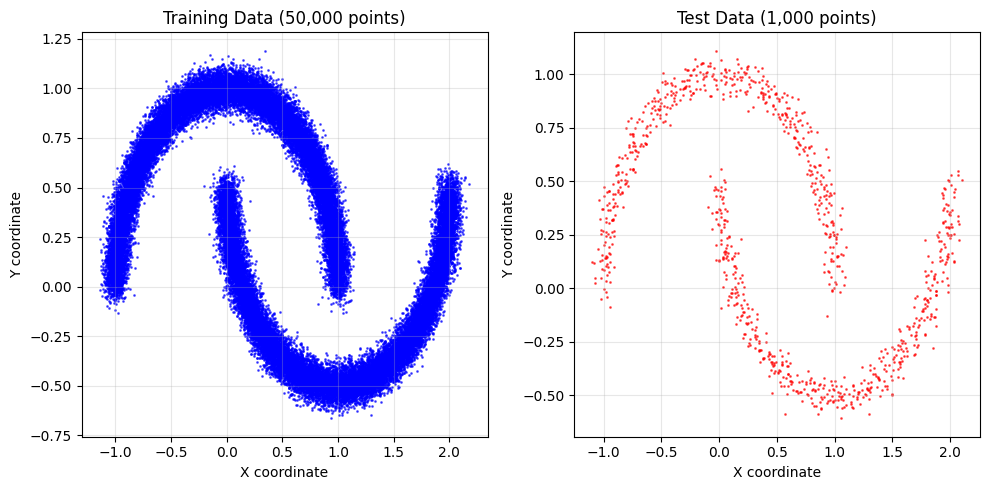

✅ Dataset created and visualized!
   Notice how the data forms two crescent moon shapes!


In [3]:
# Generate the two moons dataset
print("🌙 Generating two moons dataset...")

# Create training data (50,000 points)
train_data = datasets.make_moons(n_samples=50000, noise=0.05)[0].astype(np.float32)
print(f"   Training data shape: {train_data.shape}")

# Create test data (1,000 points)
test_data = datasets.make_moons(n_samples=1000, noise=0.05)[0].astype(np.float32)
print(f"   Test data shape: {test_data.shape}")

# Let's visualize our data
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Training Data (50,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(test_data[:, 0], test_data[:, 1], c='red', s=1, alpha=0.6)
plt.title('Test Data (1,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Dataset created and visualized!")
print("   Notice how the data forms two crescent moon shapes!")


## Step 4: Prepare Data Loaders

Data loaders help us feed data to our model in small batches during training. This is more memory-efficient than loading all data at once.


In [4]:
# Set up data loaders for efficient batch processing
print("📦 Setting up data loaders...")

# Convert numpy arrays to PyTorch tensors
train_tensor = torch.from_numpy(train_data).float()
test_tensor = torch.from_numpy(test_data).float()

print(f"   Train tensor dtype: {train_tensor.dtype}")
print(f"   Train tensor device: {train_tensor.device}")

# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_tensor, 
    batch_size=BATCH_SIZE, 
    shuffle=True,  # Randomize order for better training
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_tensor, 
    batch_size=BATCH_SIZE, 
    shuffle=False,  # No need to shuffle test data
    **kwargs
)

print(f"✅ Data loaders created!")
print(f"   Training batches: {len(train_loader)}")
print(f"   Test batches: {len(test_loader)}")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Target device: {device}")

# Let's peek at one batch to see what it looks like
sample_batch = next(iter(train_loader))
print(f"   Sample batch shape: {sample_batch.shape}")
print(f"   Sample batch dtype: {sample_batch.dtype}")
print(f"   Sample batch device: {sample_batch.device}")
print(f"   Sample batch range: [{sample_batch.min():.3f}, {sample_batch.max():.3f}]")


📦 Setting up data loaders...
   Train tensor dtype: torch.float32
   Train tensor device: cpu
✅ Data loaders created!
   Training batches: 196
   Test batches: 4
   Batch size: 256
   Target device: cuda
   Sample batch shape: torch.Size([256, 2])
   Sample batch dtype: torch.float32
   Sample batch device: cpu
   Sample batch range: [-1.032, 2.028]


## Step 5: Understanding the VAE Architecture

Now let's build our VAE model! The key idea is to have two neural networks working together:

### What is an Encoder?
The **Encoder** takes data as input and compresses it into a lower-dimensional latent space. It learns to represent data in a compact form while preserving important information.

### What is a Decoder?
The **Decoder** takes latent representations and reconstructs the original data. It learns to "decompress" the latent space back into the original data space.

### The VAE Approach
- Encoder learns a distribution over latent variables (mean and variance)
- Decoder learns to reconstruct data from latent samples
- The loss function balances reconstruction quality with latent space regularization

Let's build them step by step:


In [5]:
class VAE(nn.Module):
    """
    Variational Autoencoder with better architecture and training stability.
    """
    
    def __init__(self, input_dim, latent_dim, hidden_dim):
        super().__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        
        # Encoder network with batch normalization and dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
        )
        
        # Encoder outputs (mean and log variance)
        self.fc_mu = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim // 2, latent_dim)
        
        # Decoder network with batch normalization and dropout
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, input_dim),
        )
        
        # Initialize weights properly
        self._initialize_weights()
    
    def _initialize_weights(self):
        """Initialize network weights for better training."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def encode(self, x):
        """
        Encode input data into latent space.
        
        Args:
            x: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        # Clamp logvar to prevent numerical instability
        logvar = torch.clamp(logvar, min=-10, max=10)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick for sampling from latent distribution.
        
        Args:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        
        Returns:
            z: Sampled latent vector
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """
        Decode latent vector back to data space.
        
        Args:
            z: Latent vector of shape (batch_size, latent_dim)
        
        Returns:
            reconstructed: Reconstructed data
        """
        return self.decoder(z)
    
    def forward(self, x):
        """
        Forward pass through the VAE.
        
        Args:
            x: Input data tensor
        
        Returns:
            reconstructed: Reconstructed data
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar


print("✅ VAE class defined!")


✅ VAE class defined!


In [6]:
# Create our VAE model
print("🏗️ Creating VAE model...")

# Initialize model
vae = VAE(INPUT_DIM, LATENT_DIM, HIDDEN_DIM)

# Move model to device
vae = vae.to(device)

# Set up optimizer with weight decay
optimizer = torch.optim.Adam(vae.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate scheduler for better convergence
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20, verbose=True
)

print("✅ VAE model created!")
print(f"   Model parameters: {sum(p.numel() for p in vae.parameters()):,}")
print(f"   Learning rate: {LR}")
print(f"   Weight decay: {WEIGHT_DECAY}")
print(f"   Model moved to device: {device}")
print(f"   Learning rate scheduler: ReduceLROnPlateau")

# Let's see what our model looks like
print("\n📋 VAE architecture:")
print(vae)


🏗️ Creating VAE model...
✅ VAE model created!
   Model parameters: 808,482
   Learning rate: 0.0005
   Weight decay: 1e-05
   Model moved to device: cuda
   Learning rate scheduler: ReduceLROnPlateau

📋 VAE architecture:
VAE(
  (encoder): Sequential(
    (0): Linear(in_features=2, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=512, out_features=256, bias=True)
    (9): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (decoder): Sequential(
    (0): 

/home/engineer/miniconda3/envs/stable-diffusion/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:28: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn("The verbose parameter is deprecated. Please use get_last_lr() "


## Step 6: Understanding VAE Loss Function

Now let's understand how VAEs are trained! This is the most important part.

### The VAE Loss Function

VAEs use a special type of loss called **Evidence Lower Bound (ELBO)**:

**Reconstruction Loss:**
- Measures how well the decoder reconstructs the original data
- Usually Mean Squared Error (MSE) for continuous data

**KL Divergence Loss:**
- Measures how different the learned latent distribution is from a standard Gaussian
- Encourages the latent space to be well-structured and continuous

**Total Loss:**
- Loss = Reconstruction Loss + β × KL Divergence Loss
- β controls the balance between reconstruction quality and latent space regularization

Let's implement this:


In [7]:
def vae_loss(reconstructed, original, mu, logvar, beta=1.0):
    """
    Compute the VAE loss function with better numerical stability.
    
    Args:
        reconstructed: Reconstructed data from decoder
        original: Original input data
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: Weight for KL divergence term
    
    Returns:
        total_loss: Total VAE loss
        recon_loss: Reconstruction loss
        kl_loss: KL divergence loss
    """
    # Reconstruction loss (MSE with mean reduction for better scaling)
    recon_loss = F.mse_loss(reconstructed, original, reduction='mean')
    
    # KL divergence loss with numerical stability
    # KL(q(z|x) || p(z)) where p(z) = N(0, I)
    # closed form analytical solution for KL divergence
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    # Total loss
    total_loss = recon_loss + beta * kl_loss
    
    return total_loss, recon_loss, kl_loss

def get_beta_schedule(epoch, max_epochs, warmup_epochs):
    """
    Get beta value with warmup schedule to prevent posterior collapse.
    
    Args:
        epoch: Current epoch
        max_epochs: Total number of epochs
        warmup_epochs: Number of epochs for warmup
    
    Returns:
        beta: Current beta value
    """
    if epoch < warmup_epochs:
        # Linear warmup from 0 to BETA
        return BETA * (epoch / warmup_epochs)
    else:
        # Cyclical annealing to prevent posterior collapse
        cycle_length = 50
        cycle_position = (epoch - warmup_epochs) % cycle_length
        cycle_progress = cycle_position / cycle_length
        return BETA * (0.5 + 0.5 * np.cos(np.pi * cycle_progress))

def train_epoch(epoch):
    """
    Train the VAE for one epoch with beta scheduling.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_total_loss: Average total loss for this epoch
        avg_recon_loss: Average reconstruction loss
        avg_kl_loss: Average KL divergence loss
        current_beta: Current beta value used
    """
    vae.train()
    
    # Get current beta value with scheduling
    current_beta = get_beta_schedule(epoch, EPOCHS, BETA_WARMUP)
    
    total_losses = []
    recon_losses = []
    kl_losses = []
    
    for batch_idx, data in enumerate(train_loader):
        data = data.to(device)
        
        # Clear gradients
        optimizer.zero_grad()
        
        # Forward pass
        reconstructed, mu, logvar = vae(data)
        
        # Compute loss with current beta
        total_loss, recon_loss, kl_loss = vae_loss(reconstructed, data, mu, logvar, current_beta)
        
        # Backward pass
        total_loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Track losses
        total_losses.append(total_loss.item())
        recon_losses.append(recon_loss.item())
        kl_losses.append(kl_loss.item())
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tTotal Loss: {:.6f}\tRecon Loss: {:.6f}\tKL Loss: {:.6f}\tBeta: {:.3f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), total_loss.item(), recon_loss.item(), kl_loss.item(), current_beta))
    
    # Calculate average losses
    avg_total_loss = sum(total_losses) / len(total_losses)
    avg_recon_loss = sum(recon_losses) / len(recon_losses)
    avg_kl_loss = sum(kl_losses) / len(kl_losses)
    
    # Update learning rate scheduler
    scheduler.step(avg_total_loss)
    
    print('====> Epoch: {} Average Total Loss: {:.4f}, Average Recon Loss: {:.4f}, Average KL Loss: {:.4f}, Beta: {:.3f}'.format(
        epoch, avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta))
    
    return avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta

print("✅ VAE loss function and training epoch function defined!")

✅ VAE loss function and training epoch function defined!


## Step 7: Visualization and Sampling Functions

Now let's create functions to visualize our training progress and generate samples. This will help us see how well our VAE is learning!


In [8]:
def generate_samples(num_samples=1000):
    """
    Generate new samples using the VAE decoder.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        generated_samples: Generated data as numpy array
    """
    vae.eval()
    
    with torch.no_grad():
        # Sample from standard Gaussian in latent space
        z = torch.randn(num_samples, LATENT_DIM, device=device)
        
        # Decode to generate samples
        generated_samples = vae.decode(z)
        
        # Convert to numpy for visualization
        generated_samples = generated_samples.cpu().numpy()
    
    return generated_samples

def visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=False):
    """
    Visualize the current state of our VAE training.
    
    Args:
        epoch: Current epoch number
        total_losses: List of total losses
        recon_losses: List of reconstruction losses
        kl_losses: List of KL divergence losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(generated_samples[:, 0], generated_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(generated_samples[:, 0], generated_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Original vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Loss plots
    if len(total_losses) > 0:
        epochs_range = range(1, len(total_losses) + 1)
        
        # Total loss
        plt.subplot(2, 3, 4)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Total Loss')
        plt.title('Total Loss Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Reconstruction and KL losses
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=2)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss Components')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=1, alpha=0.7)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=1, alpha=0.7)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('All Losses Combined')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save plot if requested
    if save_plot:
        if not os.path.exists('vae_results'):
            os.makedirs('vae_results')
        plt.savefig(f'vae_results/vae_progress_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        print(f"💾 Saved plot: vae_results/vae_progress_epoch_{epoch}.png")
    
    plt.show()

print("✅ Visualization and sampling functions defined!")
print("   These functions help us see how well our VAE is learning.")


✅ Visualization and sampling functions defined!
   These functions help us see how well our VAE is learning.


## Step 8: Let's Train Our VAE! 🚀

Now comes the exciting part - training our VAE! We'll run through multiple epochs and watch as our model learns to encode and decode moon-shaped data while maintaining a well-structured latent space.


🎯 Starting VAE training...
📊 Initial state (before training):
💾 Saved plot: vae_results/vae_progress_epoch_0.png


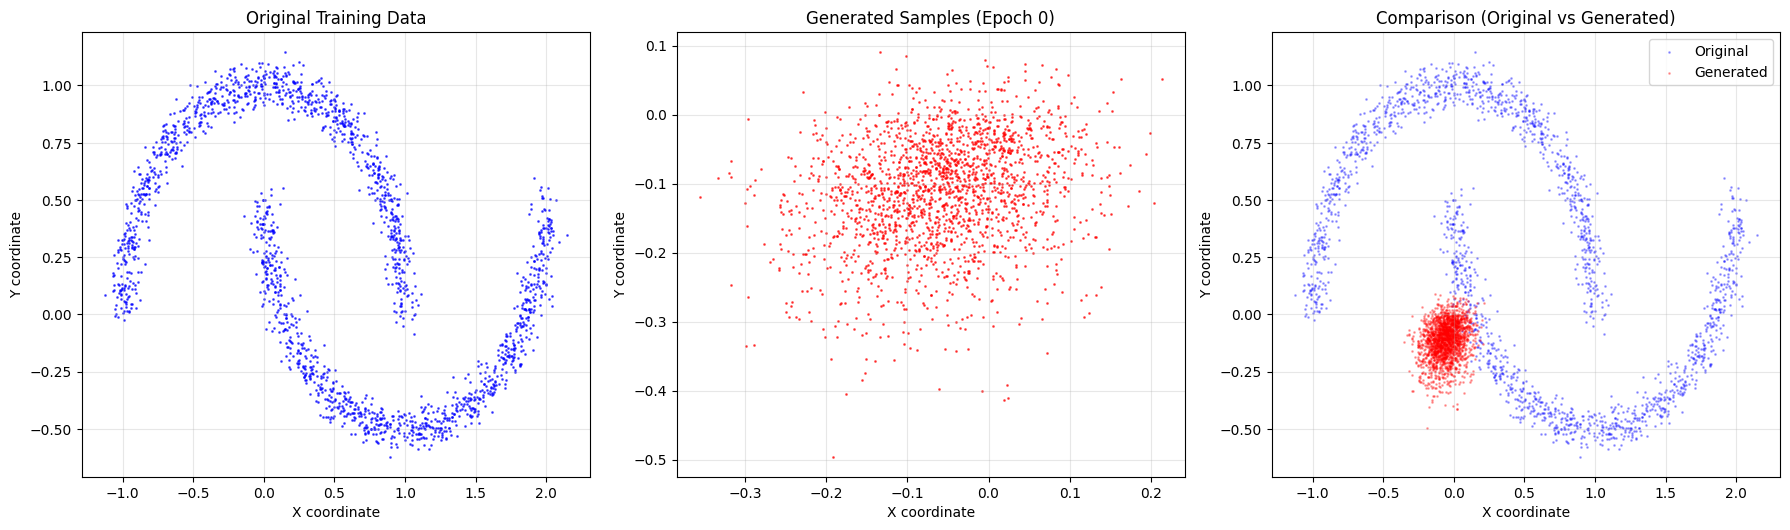


📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/50000 (0%)]	Total Loss: 1.482828	Recon Loss: 1.474048	KL Loss: 0.878046	Beta: 0.010
Epoch: 1 [12800/50000 (26%)]	Total Loss: 0.222764	Recon Loss: 0.200511	KL Loss: 2.225357	Beta: 0.010
Epoch: 1 [25600/50000 (51%)]	Total Loss: 0.127797	Recon Loss: 0.109276	KL Loss: 1.852105	Beta: 0.010
Epoch: 1 [38400/50000 (77%)]	Total Loss: 0.110973	Recon Loss: 0.095931	KL Loss: 1.504183	Beta: 0.010
====> Epoch: 1 Average Total Loss: 0.1968, Average Recon Loss: 0.1748, Average KL Loss: 2.1990, Beta: 0.010
📈 Epoch 1 Summary:
   Total Loss: 0.1968
   Reconstruction Loss: 0.1748
   KL Divergence Loss: 2.1990
   Beta: 0.010
   Learning Rate: 0.000500

📊 Epoch 2/200
----------------------------------------
Epoch: 2 [0/50000 (0%)]	Total Loss: 0.076137	Recon Loss: 0.051242	KL Loss: 1.244751	Beta: 0.020
Epoch: 2 [12800/50000 (26%)]	Total Loss: 0.078706	Recon Loss: 0.060473	KL Loss: 0.911644	Beta: 0.020
Epoch: 2 [25600/50000 (51%)]	Total Loss:

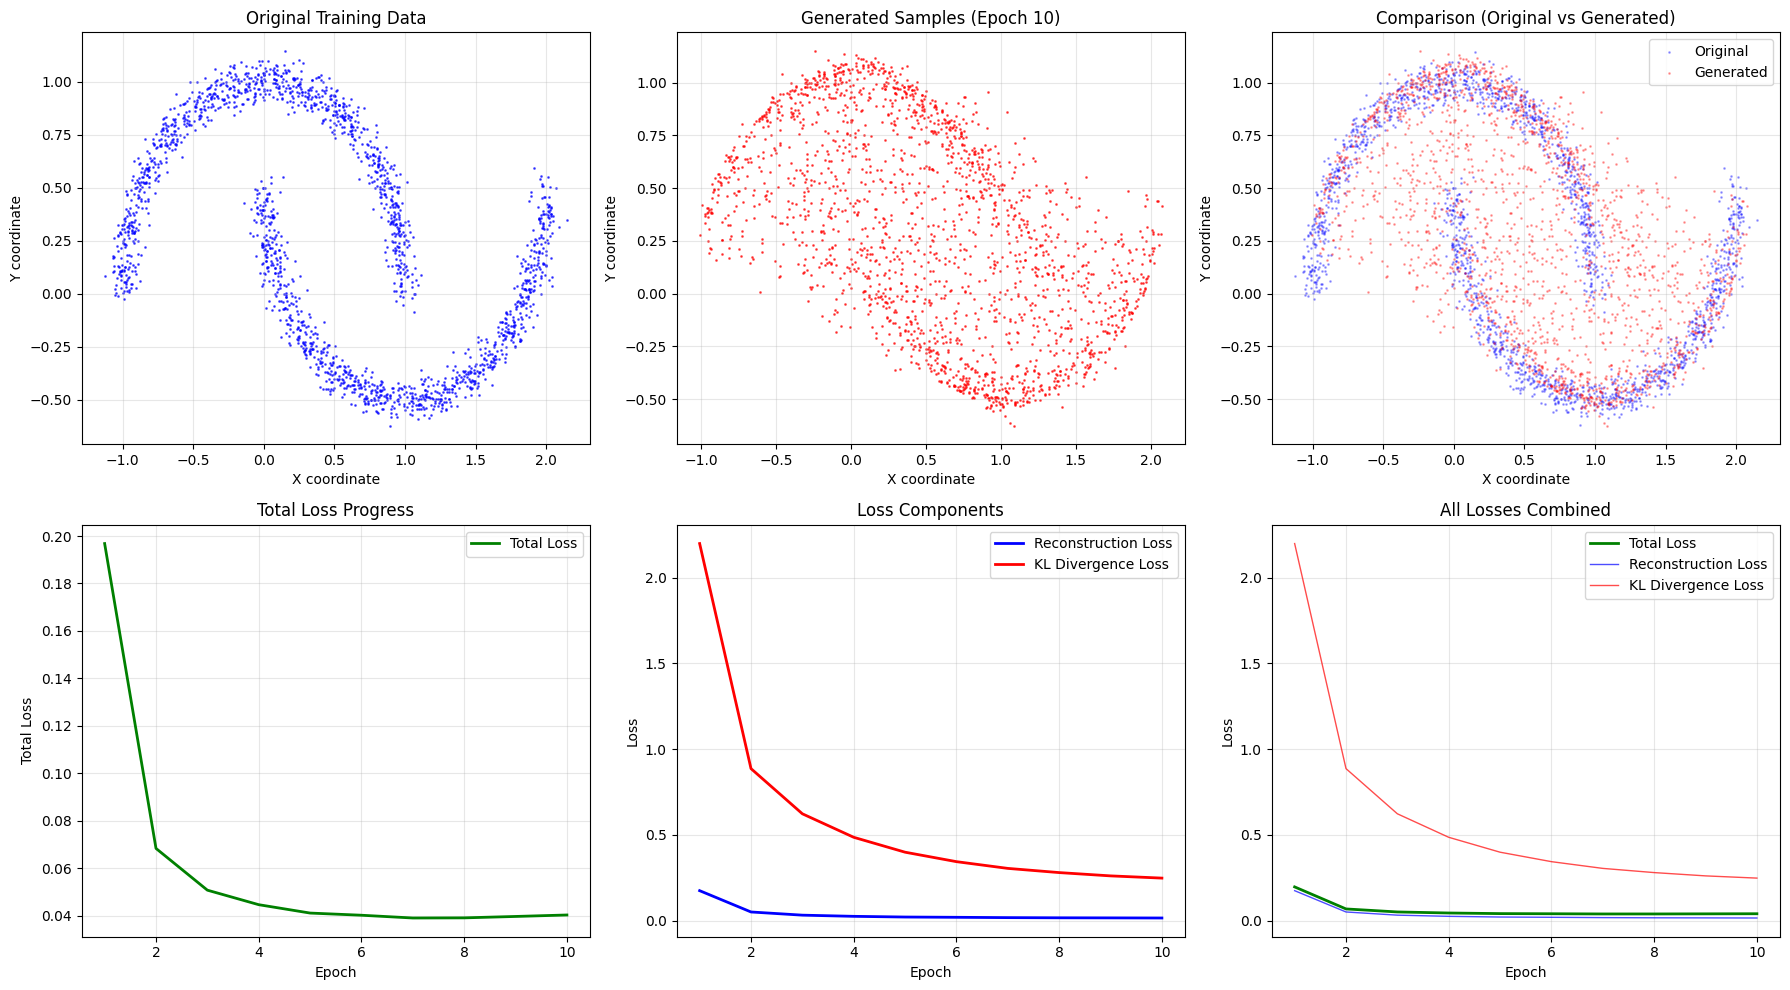

📈 Epoch 10 Summary:
   Total Loss: 0.0403
   Reconstruction Loss: 0.0155
   KL Divergence Loss: 0.2481
   Beta: 0.100
   Learning Rate: 0.000500

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/50000 (0%)]	Total Loss: 0.040962	Recon Loss: 0.013869	KL Loss: 0.246298	Beta: 0.110
Epoch: 11 [12800/50000 (26%)]	Total Loss: 0.039807	Recon Loss: 0.014001	KL Loss: 0.234597	Beta: 0.110
Epoch: 11 [25600/50000 (51%)]	Total Loss: 0.038701	Recon Loss: 0.012311	KL Loss: 0.239910	Beta: 0.110
Epoch: 11 [38400/50000 (77%)]	Total Loss: 0.043513	Recon Loss: 0.017608	KL Loss: 0.235498	Beta: 0.110
====> Epoch: 11 Average Total Loss: 0.0411, Average Recon Loss: 0.0150, Average KL Loss: 0.2380, Beta: 0.110
📈 Epoch 11 Summary:
   Total Loss: 0.0411
   Reconstruction Loss: 0.0150
   KL Divergence Loss: 0.2380
   Beta: 0.110
   Learning Rate: 0.000500

📊 Epoch 12/200
----------------------------------------
Epoch: 12 [0/50000 (0%)]	Total Loss: 0.042453	Recon Loss: 0.013870	KL Loss: 0.238187

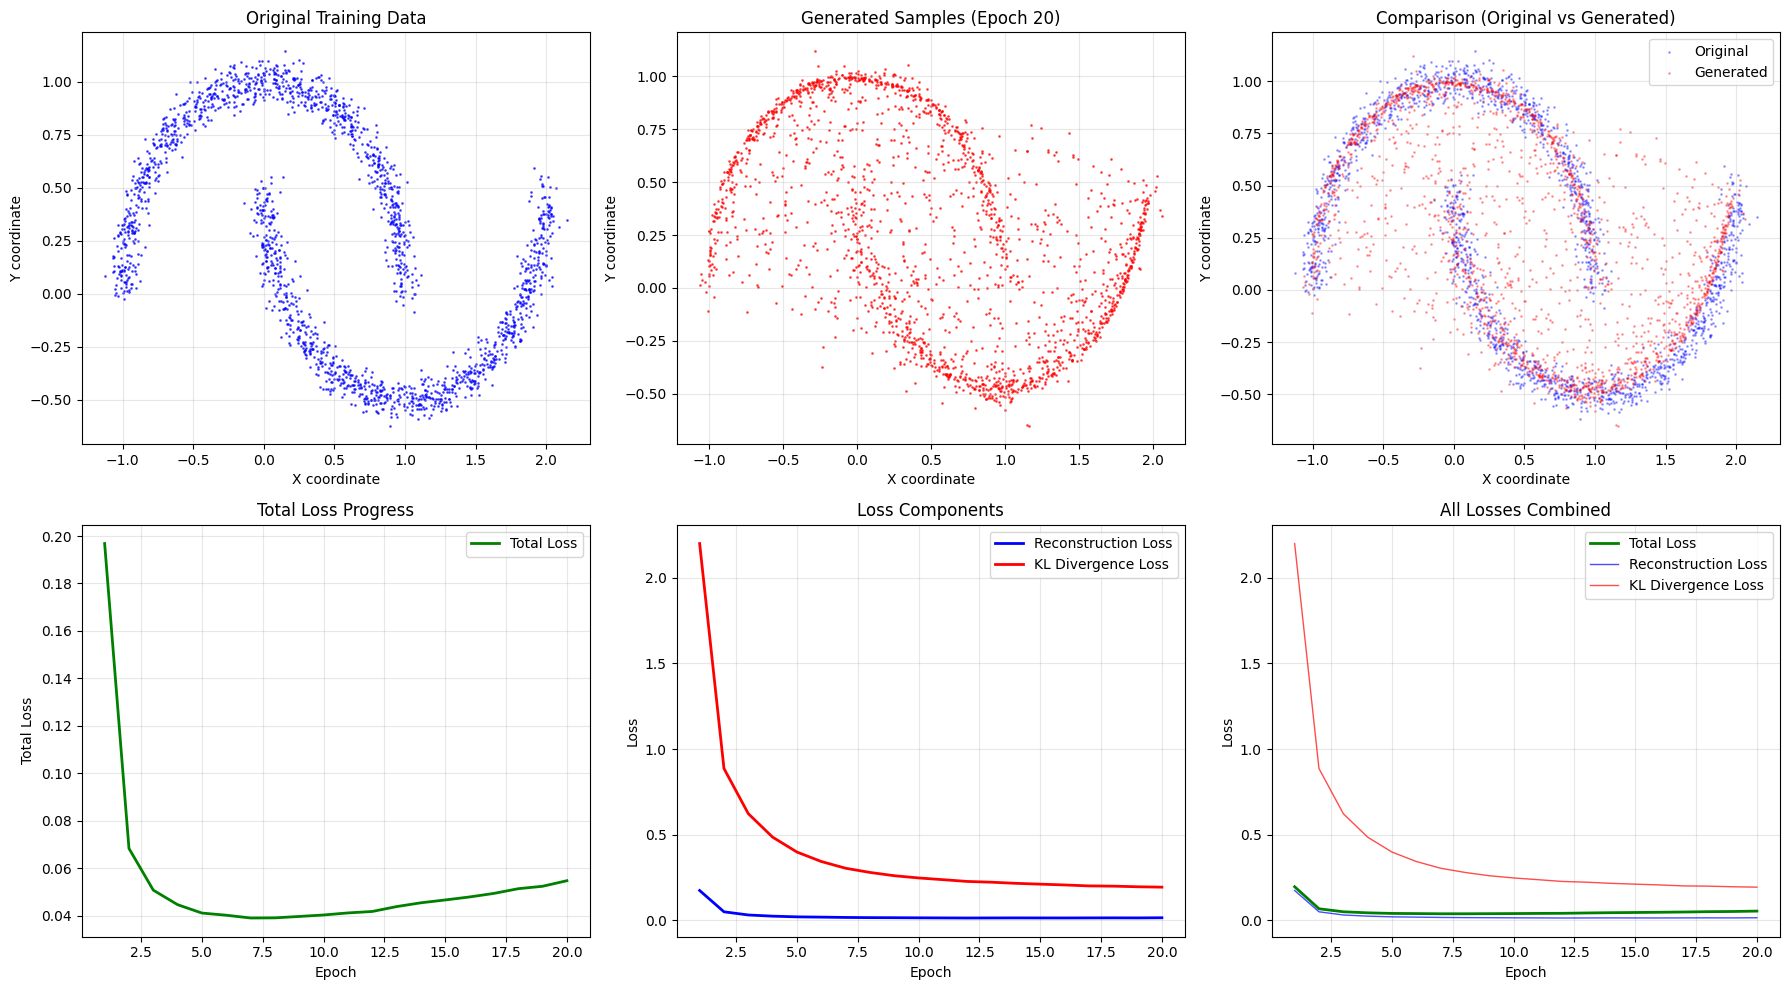

📈 Epoch 20 Summary:
   Total Loss: 0.0547
   Reconstruction Loss: 0.0158
   KL Divergence Loss: 0.1944
   Beta: 0.200
   Learning Rate: 0.000500

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/50000 (0%)]	Total Loss: 0.055031	Recon Loss: 0.013912	KL Loss: 0.195807	Beta: 0.210
Epoch: 21 [12800/50000 (26%)]	Total Loss: 0.053305	Recon Loss: 0.013017	KL Loss: 0.191849	Beta: 0.210
Epoch: 21 [25600/50000 (51%)]	Total Loss: 0.055345	Recon Loss: 0.015708	KL Loss: 0.188749	Beta: 0.210
Epoch: 21 [38400/50000 (77%)]	Total Loss: 0.063920	Recon Loss: 0.023082	KL Loss: 0.194469	Beta: 0.210
====> Epoch: 21 Average Total Loss: 0.0559, Average Recon Loss: 0.0158, Average KL Loss: 0.1909, Beta: 0.210
📈 Epoch 21 Summary:
   Total Loss: 0.0559
   Reconstruction Loss: 0.0158
   KL Divergence Loss: 0.1909
   Beta: 0.210
   Learning Rate: 0.000500

📊 Epoch 22/200
----------------------------------------
Epoch: 22 [0/50000 (0%)]	Total Loss: 0.057182	Recon Loss: 0.014868	KL Loss: 0.192336

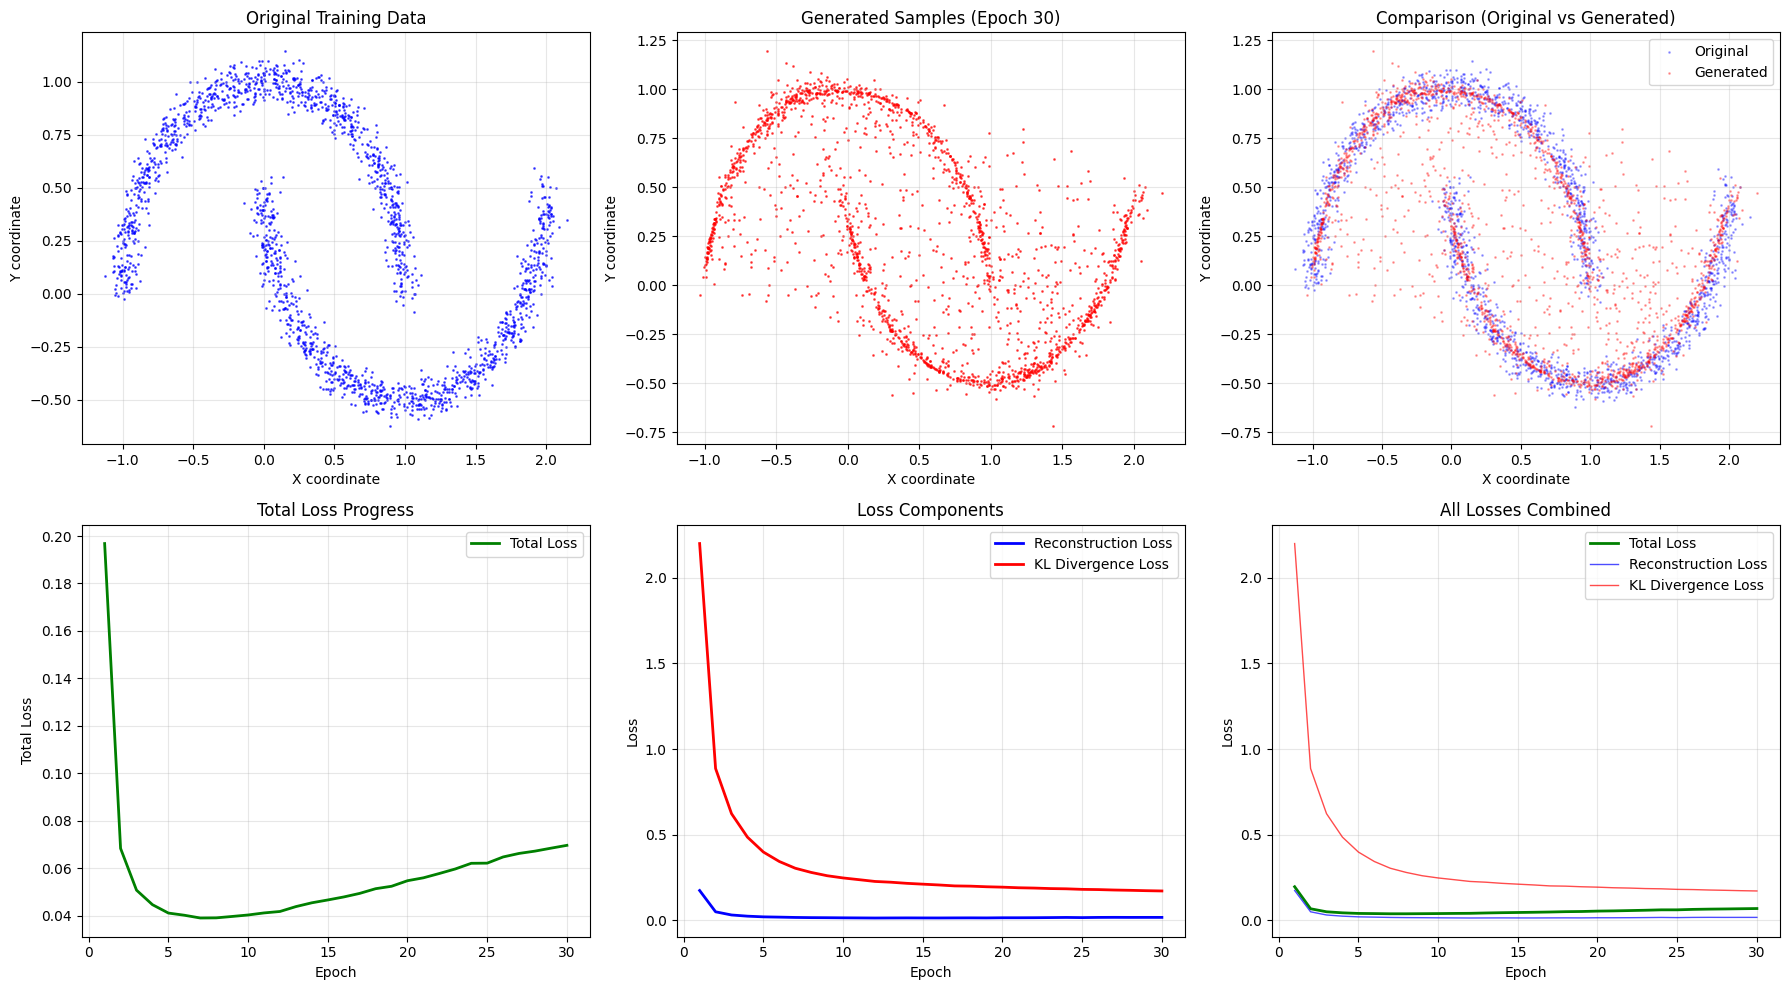

📈 Epoch 30 Summary:
   Total Loss: 0.0696
   Reconstruction Loss: 0.0180
   KL Divergence Loss: 0.1721
   Beta: 0.300
   Learning Rate: 0.000250

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/50000 (0%)]	Total Loss: 0.071853	Recon Loss: 0.017932	KL Loss: 0.173940	Beta: 0.310
Epoch: 31 [12800/50000 (26%)]	Total Loss: 0.072991	Recon Loss: 0.019347	KL Loss: 0.173046	Beta: 0.310
Epoch: 31 [25600/50000 (51%)]	Total Loss: 0.069707	Recon Loss: 0.017185	KL Loss: 0.169423	Beta: 0.310
Epoch: 31 [38400/50000 (77%)]	Total Loss: 0.070395	Recon Loss: 0.018282	KL Loss: 0.168109	Beta: 0.310
====> Epoch: 31 Average Total Loss: 0.0715, Average Recon Loss: 0.0183, Average KL Loss: 0.1716, Beta: 0.310
📈 Epoch 31 Summary:
   Total Loss: 0.0715
   Reconstruction Loss: 0.0183
   KL Divergence Loss: 0.1716
   Beta: 0.310
   Learning Rate: 0.000250

📊 Epoch 32/200
----------------------------------------
Epoch: 32 [0/50000 (0%)]	Total Loss: 0.074585	Recon Loss: 0.019393	KL Loss: 0.172475

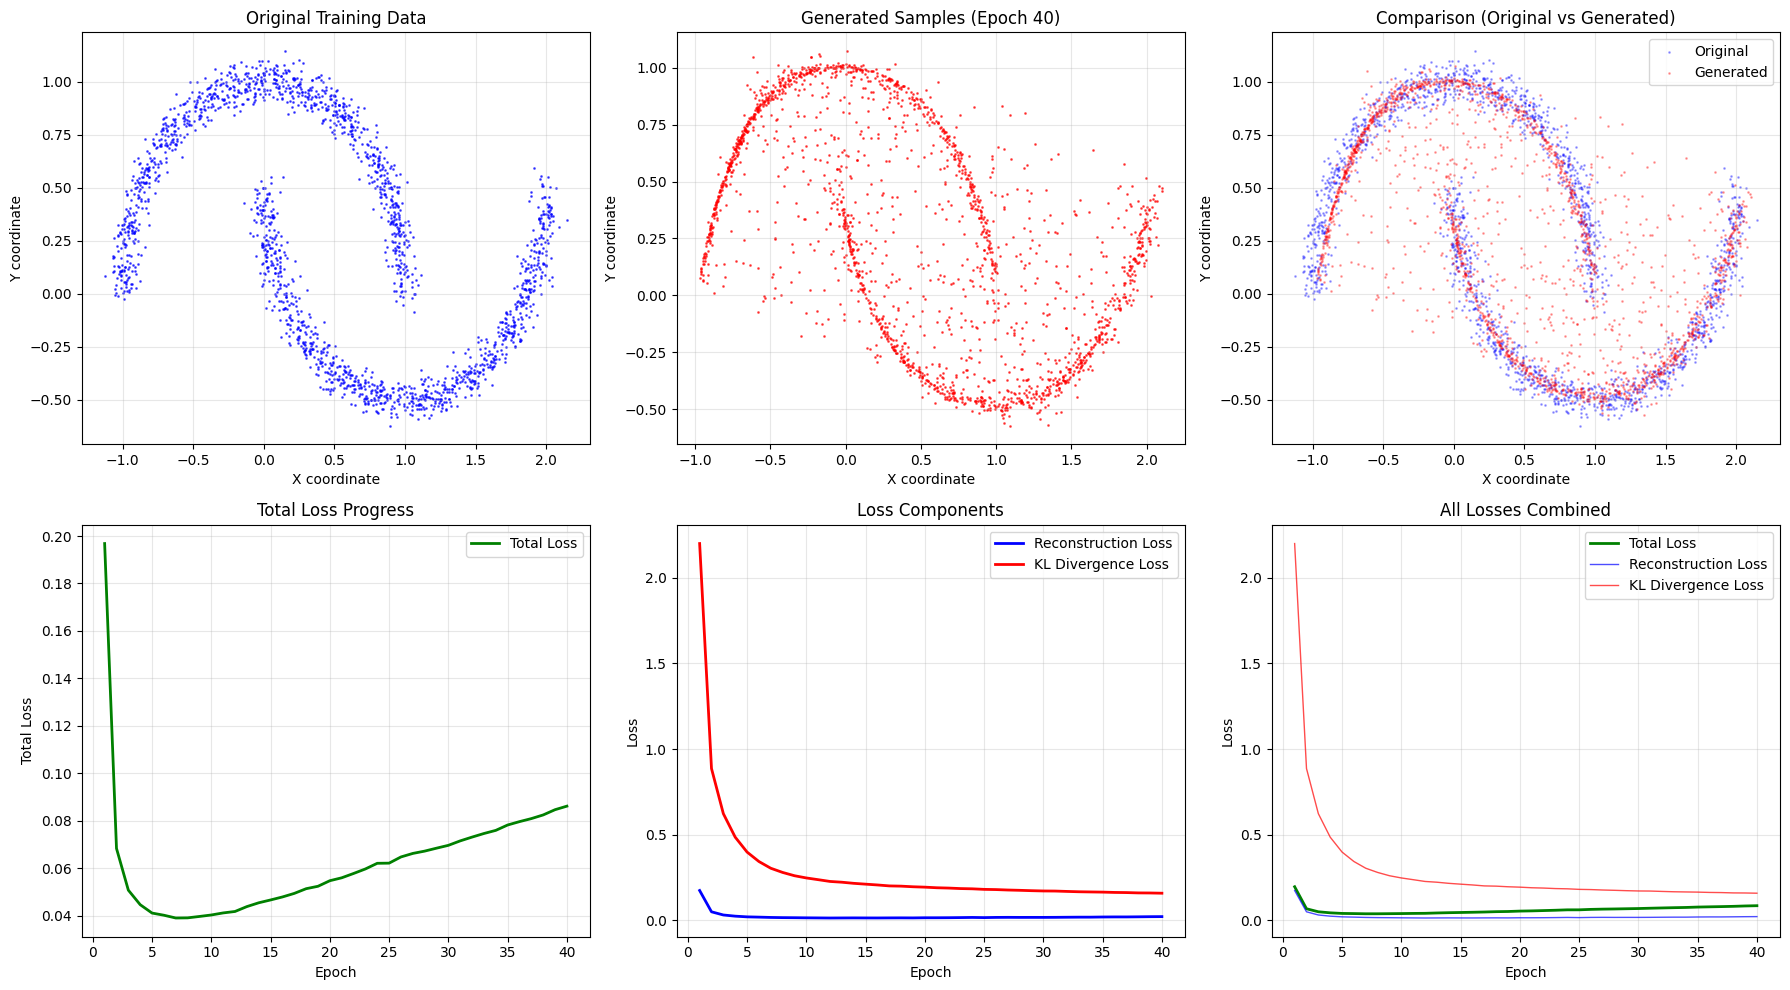

📈 Epoch 40 Summary:
   Total Loss: 0.0861
   Reconstruction Loss: 0.0225
   KL Divergence Loss: 0.1591
   Beta: 0.400
   Learning Rate: 0.000250

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/50000 (0%)]	Total Loss: 0.088342	Recon Loss: 0.022787	KL Loss: 0.159891	Beta: 0.410
Epoch: 41 [12800/50000 (26%)]	Total Loss: 0.089540	Recon Loss: 0.024804	KL Loss: 0.157892	Beta: 0.410
Epoch: 41 [25600/50000 (51%)]	Total Loss: 0.090079	Recon Loss: 0.027075	KL Loss: 0.153667	Beta: 0.410
Epoch: 41 [38400/50000 (77%)]	Total Loss: 0.088031	Recon Loss: 0.025384	KL Loss: 0.152797	Beta: 0.410
====> Epoch: 41 Average Total Loss: 0.0875, Average Recon Loss: 0.0227, Average KL Loss: 0.1580, Beta: 0.410
📈 Epoch 41 Summary:
   Total Loss: 0.0875
   Reconstruction Loss: 0.0227
   KL Divergence Loss: 0.1580
   Beta: 0.410
   Learning Rate: 0.000250

📊 Epoch 42/200
----------------------------------------
Epoch: 42 [0/50000 (0%)]	Total Loss: 0.088407	Recon Loss: 0.021325	KL Loss: 0.159721

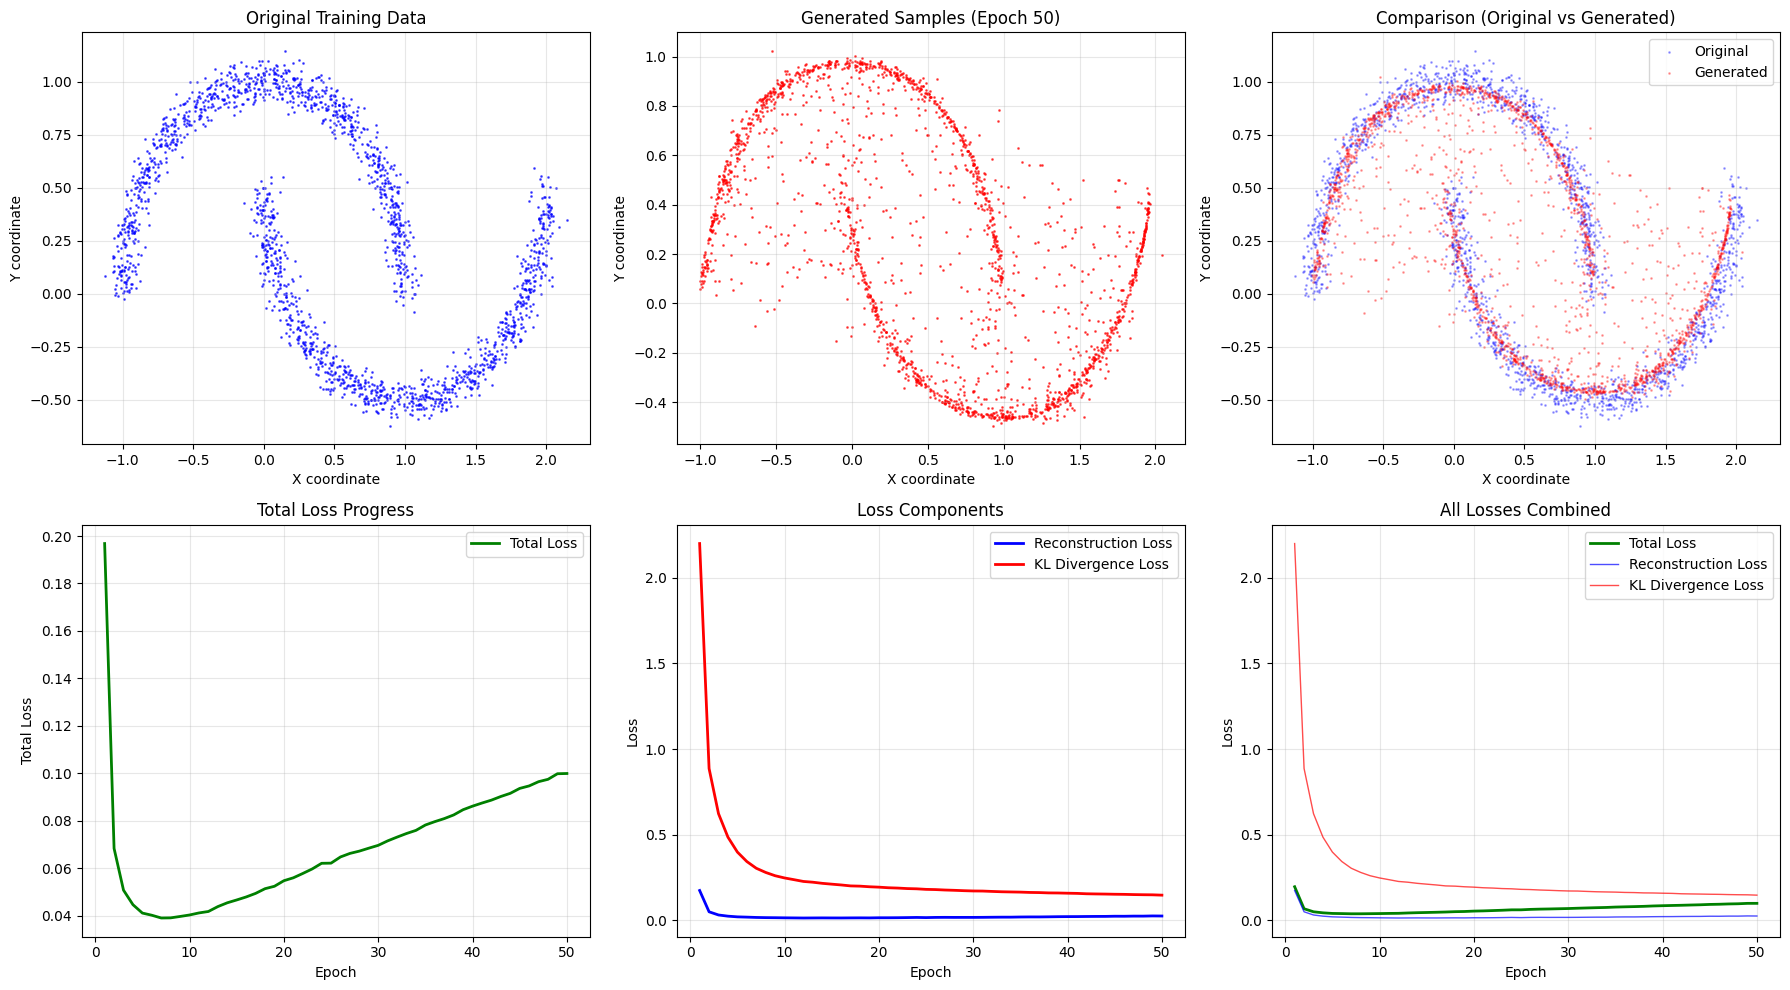

📈 Epoch 50 Summary:
   Total Loss: 0.0999
   Reconstruction Loss: 0.0260
   KL Divergence Loss: 0.1478
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/50000 (0%)]	Total Loss: 0.101356	Recon Loss: 0.027105	KL Loss: 0.148649	Beta: 0.500
Epoch: 51 [12800/50000 (26%)]	Total Loss: 0.101063	Recon Loss: 0.024017	KL Loss: 0.154243	Beta: 0.500
Epoch: 51 [25600/50000 (51%)]	Total Loss: 0.099054	Recon Loss: 0.025942	KL Loss: 0.146369	Beta: 0.500
Epoch: 51 [38400/50000 (77%)]	Total Loss: 0.091527	Recon Loss: 0.018150	KL Loss: 0.146900	Beta: 0.500
====> Epoch: 51 Average Total Loss: 0.0996, Average Recon Loss: 0.0259, Average KL Loss: 0.1475, Beta: 0.500
📈 Epoch 51 Summary:
   Total Loss: 0.0996
   Reconstruction Loss: 0.0259
   KL Divergence Loss: 0.1475
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 52/200
----------------------------------------
Epoch: 52 [0/50000 (0%)]	Total Loss: 0.098357	Recon Loss: 0.024840	KL Loss: 0.147616

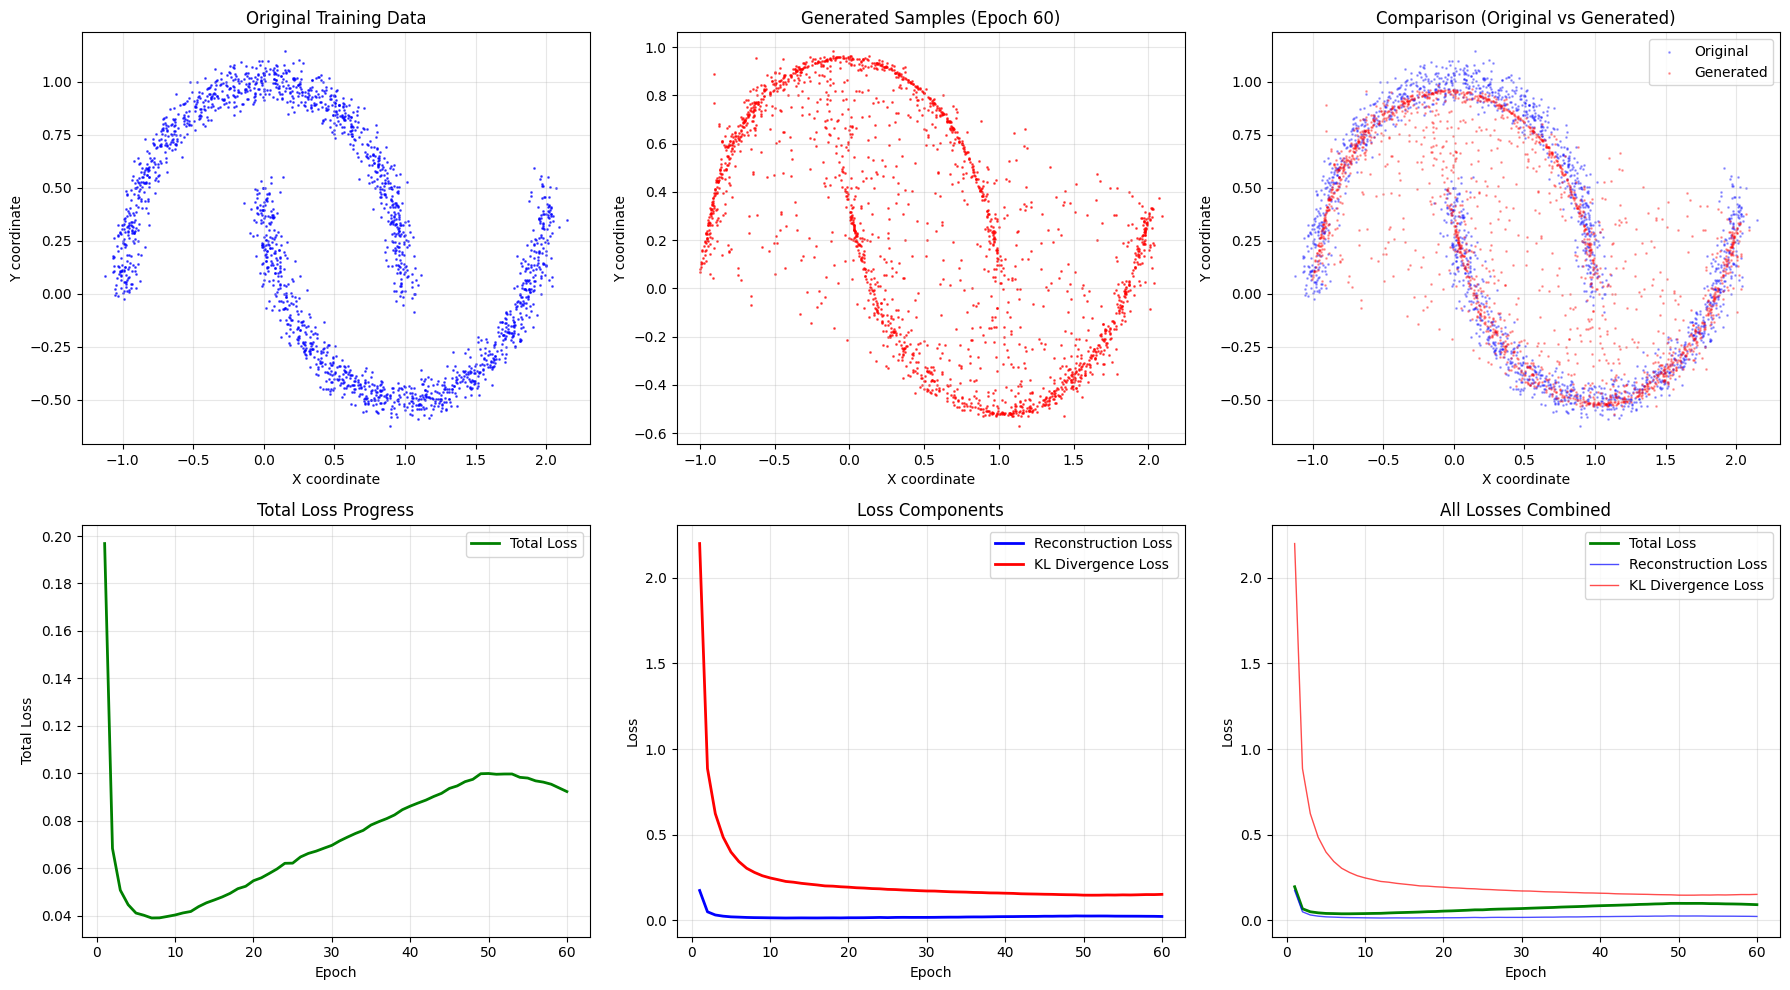

📈 Epoch 60 Summary:
   Total Loss: 0.0923
   Reconstruction Loss: 0.0234
   KL Divergence Loss: 0.1523
   Beta: 0.452
   Learning Rate: 0.000125

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/50000 (0%)]	Total Loss: 0.094950	Recon Loss: 0.026999	KL Loss: 0.153517	Beta: 0.443
Epoch: 61 [12800/50000 (26%)]	Total Loss: 0.094969	Recon Loss: 0.026195	KL Loss: 0.155378	Beta: 0.443
Epoch: 61 [25600/50000 (51%)]	Total Loss: 0.089883	Recon Loss: 0.021160	KL Loss: 0.155262	Beta: 0.443
Epoch: 61 [38400/50000 (77%)]	Total Loss: 0.090346	Recon Loss: 0.022466	KL Loss: 0.153357	Beta: 0.443
====> Epoch: 61 Average Total Loss: 0.0913, Average Recon Loss: 0.0234, Average KL Loss: 0.1533, Beta: 0.443
📈 Epoch 61 Summary:
   Total Loss: 0.0913
   Reconstruction Loss: 0.0234
   KL Divergence Loss: 0.1533
   Beta: 0.443
   Learning Rate: 0.000125

📊 Epoch 62/200
----------------------------------------
Epoch: 62 [0/50000 (0%)]	Total Loss: 0.094108	Recon Loss: 0.027908	KL Loss: 0.153157

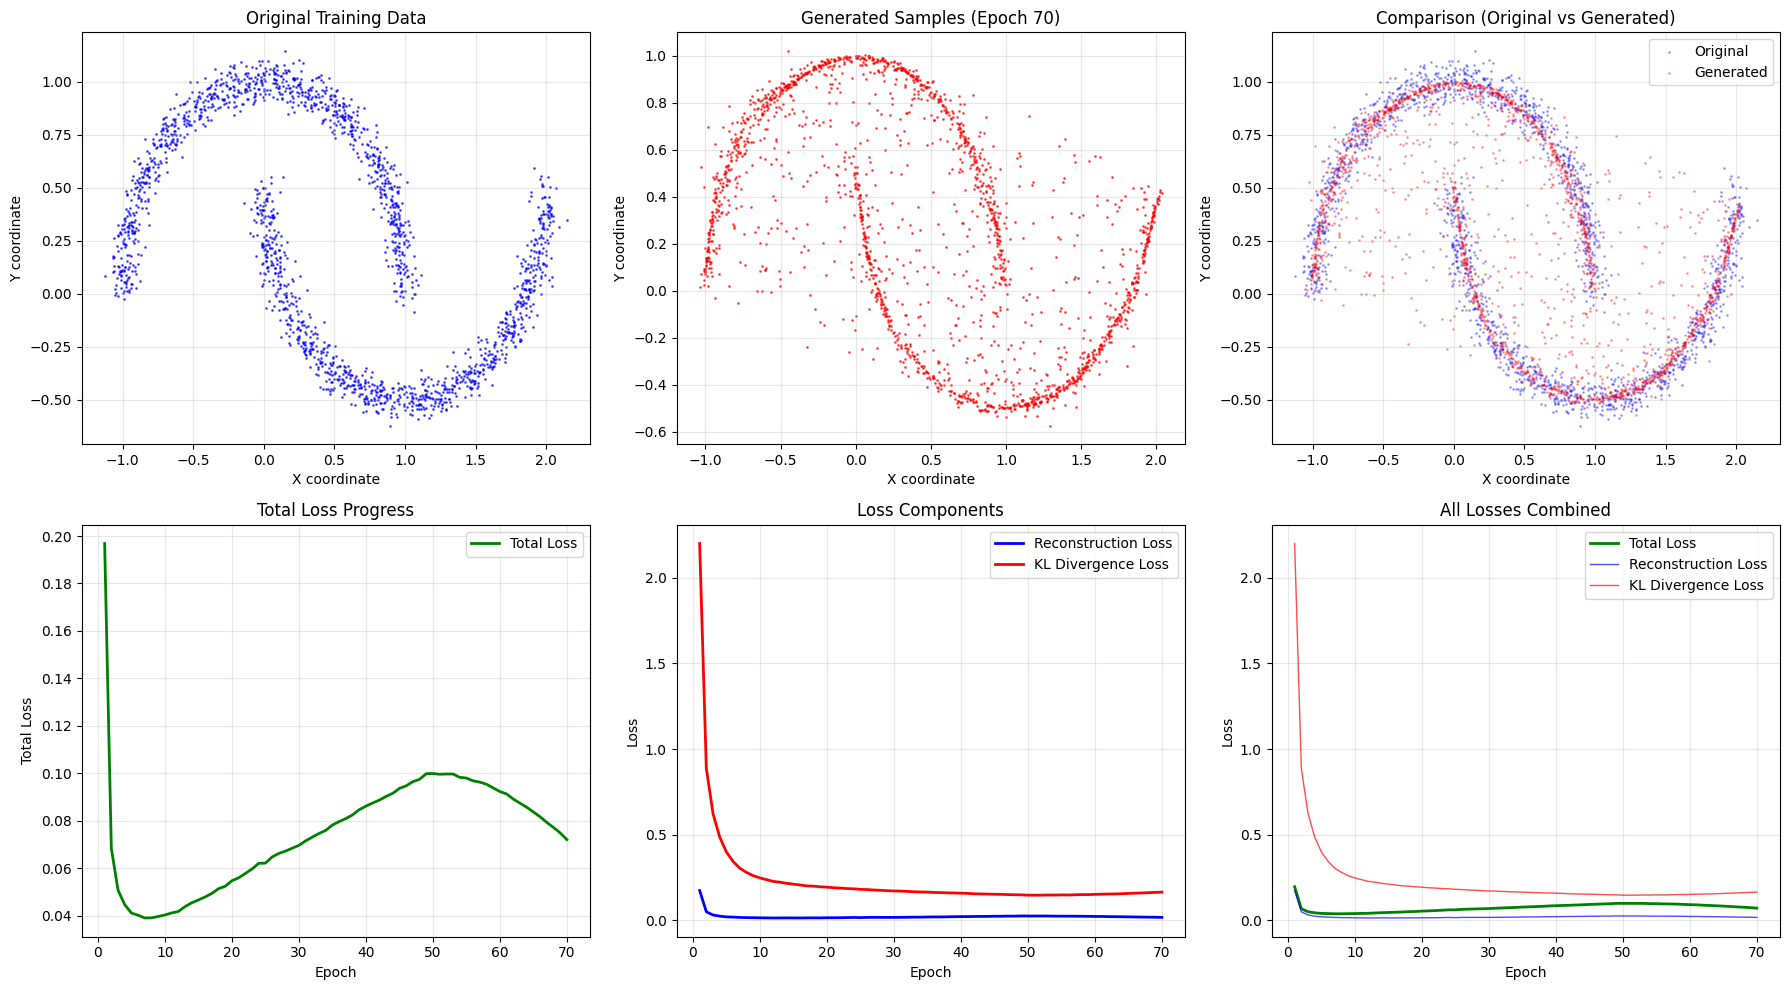

📈 Epoch 70 Summary:
   Total Loss: 0.0720
   Reconstruction Loss: 0.0179
   KL Divergence Loss: 0.1654
   Beta: 0.327
   Learning Rate: 0.000063

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/50000 (0%)]	Total Loss: 0.069544	Recon Loss: 0.017790	KL Loss: 0.165786	Beta: 0.312
Epoch: 71 [12800/50000 (26%)]	Total Loss: 0.070551	Recon Loss: 0.017562	KL Loss: 0.169743	Beta: 0.312
Epoch: 71 [25600/50000 (51%)]	Total Loss: 0.072873	Recon Loss: 0.019477	KL Loss: 0.171044	Beta: 0.312
Epoch: 71 [38400/50000 (77%)]	Total Loss: 0.069383	Recon Loss: 0.017272	KL Loss: 0.166932	Beta: 0.312
====> Epoch: 71 Average Total Loss: 0.0692, Average Recon Loss: 0.0169, Average KL Loss: 0.1675, Beta: 0.312
📈 Epoch 71 Summary:
   Total Loss: 0.0692
   Reconstruction Loss: 0.0169
   KL Divergence Loss: 0.1675
   Beta: 0.312
   Learning Rate: 0.000063

📊 Epoch 72/200
----------------------------------------
Epoch: 72 [0/50000 (0%)]	Total Loss: 0.064500	Recon Loss: 0.014350	KL Loss: 0.168943

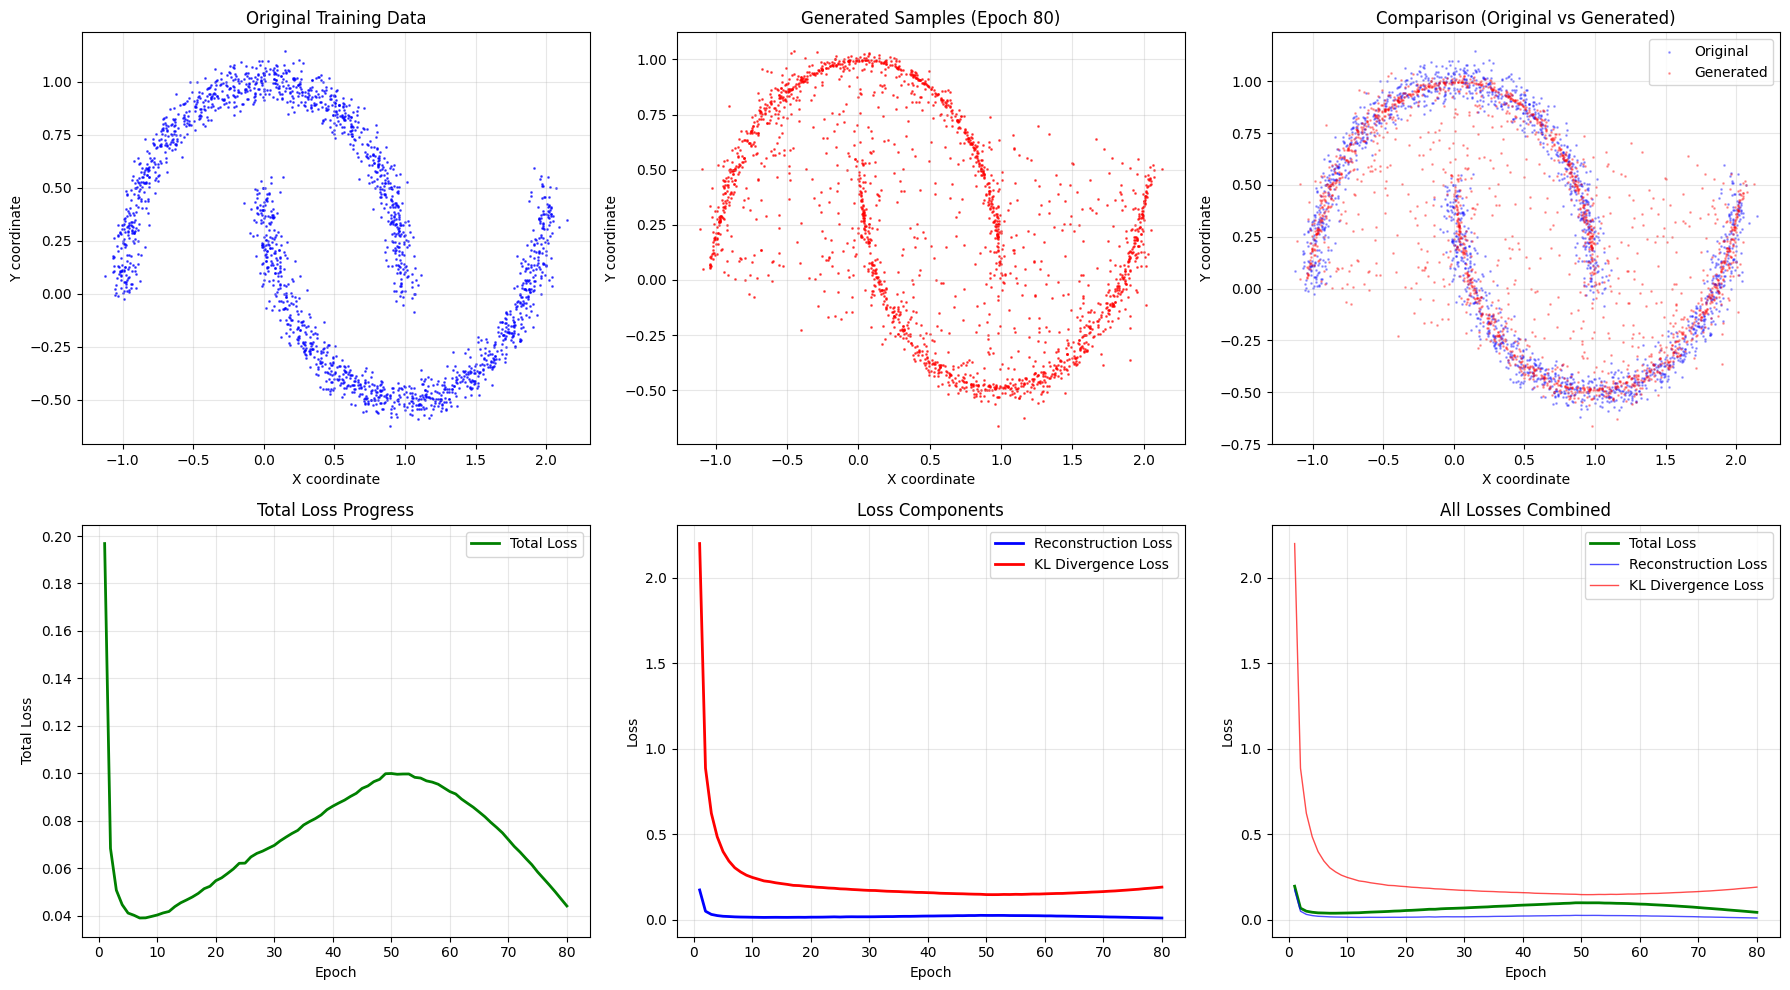

📈 Epoch 80 Summary:
   Total Loss: 0.0441
   Reconstruction Loss: 0.0110
   KL Divergence Loss: 0.1914
   Beta: 0.173
   Learning Rate: 0.000063

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/50000 (0%)]	Total Loss: 0.042348	Recon Loss: 0.012291	KL Loss: 0.190269	Beta: 0.158
Epoch: 81 [12800/50000 (26%)]	Total Loss: 0.041806	Recon Loss: 0.010823	KL Loss: 0.196138	Beta: 0.158
Epoch: 81 [25600/50000 (51%)]	Total Loss: 0.039770	Recon Loss: 0.008832	KL Loss: 0.195847	Beta: 0.158
Epoch: 81 [38400/50000 (77%)]	Total Loss: 0.041388	Recon Loss: 0.010736	KL Loss: 0.194041	Beta: 0.158
====> Epoch: 81 Average Total Loss: 0.0414, Average Recon Loss: 0.0104, Average KL Loss: 0.1959, Beta: 0.158
📈 Epoch 81 Summary:
   Total Loss: 0.0414
   Reconstruction Loss: 0.0104
   KL Divergence Loss: 0.1959
   Beta: 0.158
   Learning Rate: 0.000063

📊 Epoch 82/200
----------------------------------------
Epoch: 82 [0/50000 (0%)]	Total Loss: 0.037865	Recon Loss: 0.009748	KL Loss: 0.195864

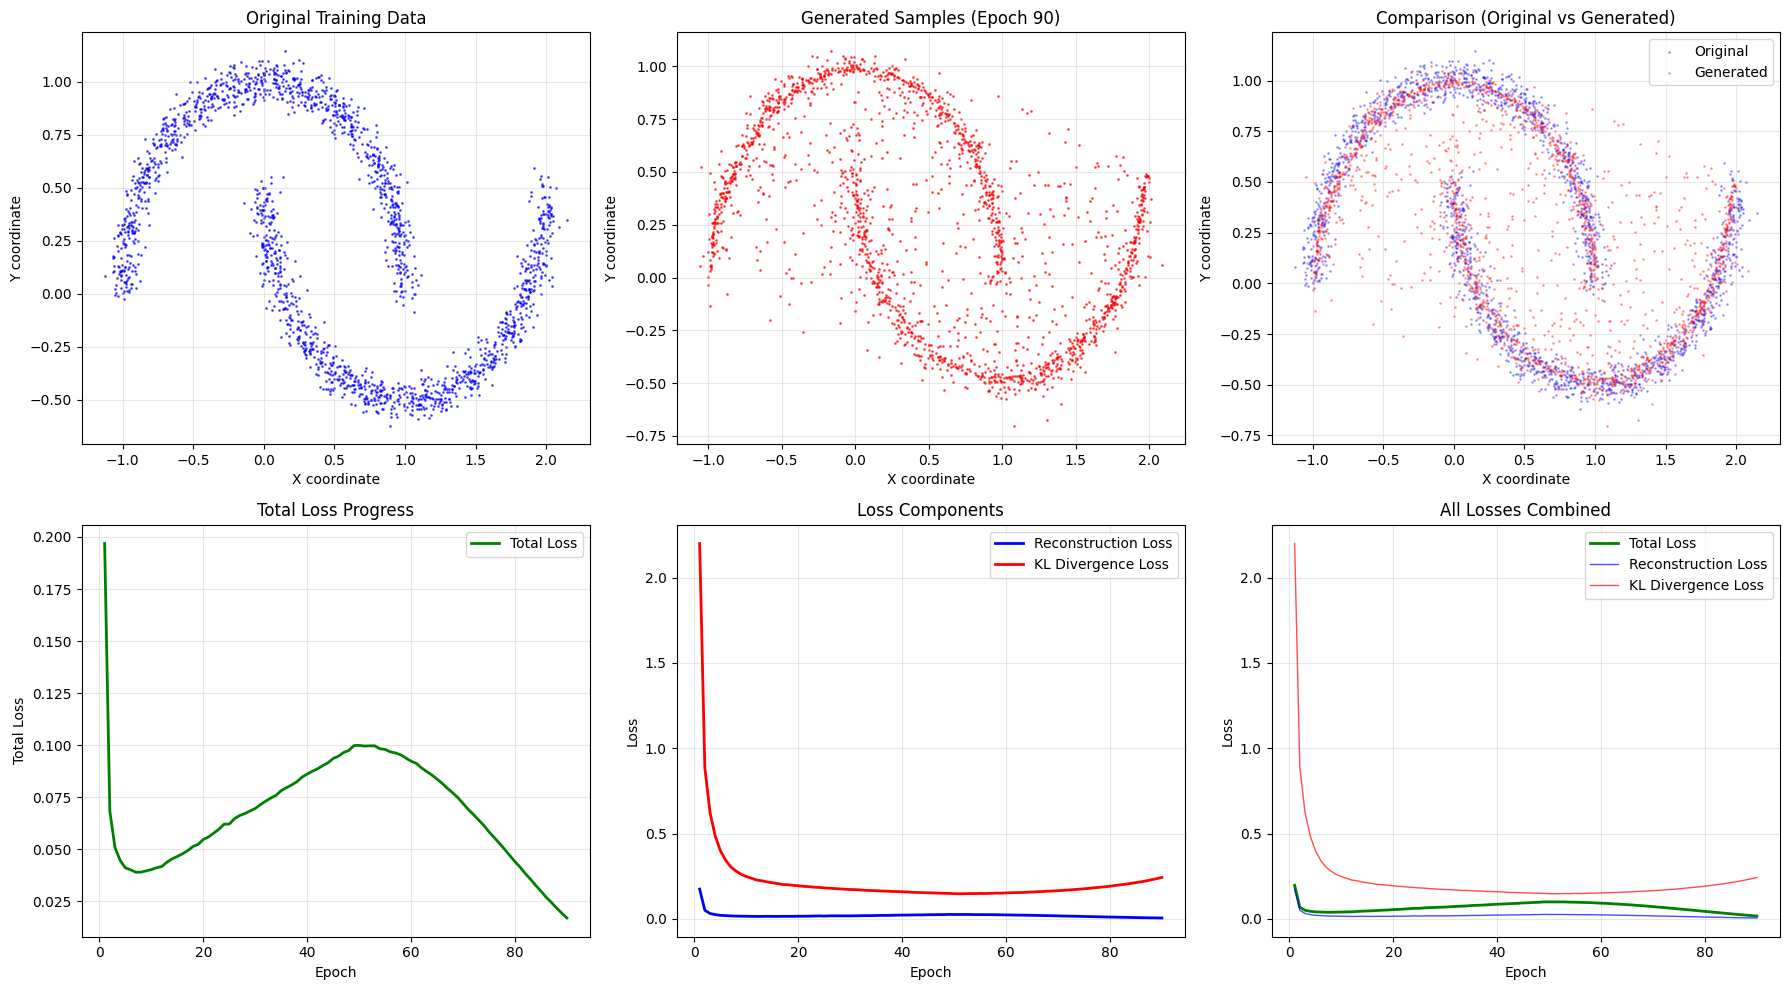

📈 Epoch 90 Summary:
   Total Loss: 0.0170
   Reconstruction Loss: 0.0054
   KL Divergence Loss: 0.2430
   Beta: 0.048
   Learning Rate: 0.000063

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/50000 (0%)]	Total Loss: 0.015240	Recon Loss: 0.005723	KL Loss: 0.244528	Beta: 0.039
Epoch: 91 [12800/50000 (26%)]	Total Loss: 0.013838	Recon Loss: 0.004130	KL Loss: 0.249428	Beta: 0.039
Epoch: 91 [25600/50000 (51%)]	Total Loss: 0.014223	Recon Loss: 0.004344	KL Loss: 0.253839	Beta: 0.039
Epoch: 91 [38400/50000 (77%)]	Total Loss: 0.014307	Recon Loss: 0.004439	KL Loss: 0.253556	Beta: 0.039
====> Epoch: 91 Average Total Loss: 0.0148, Average Recon Loss: 0.0050, Average KL Loss: 0.2513, Beta: 0.039
📈 Epoch 91 Summary:
   Total Loss: 0.0148
   Reconstruction Loss: 0.0050
   KL Divergence Loss: 0.2513
   Beta: 0.039
   Learning Rate: 0.000063

📊 Epoch 92/200
----------------------------------------
Epoch: 92 [0/50000 (0%)]	Total Loss: 0.015263	Recon Loss: 0.007453	KL Loss: 0.252564

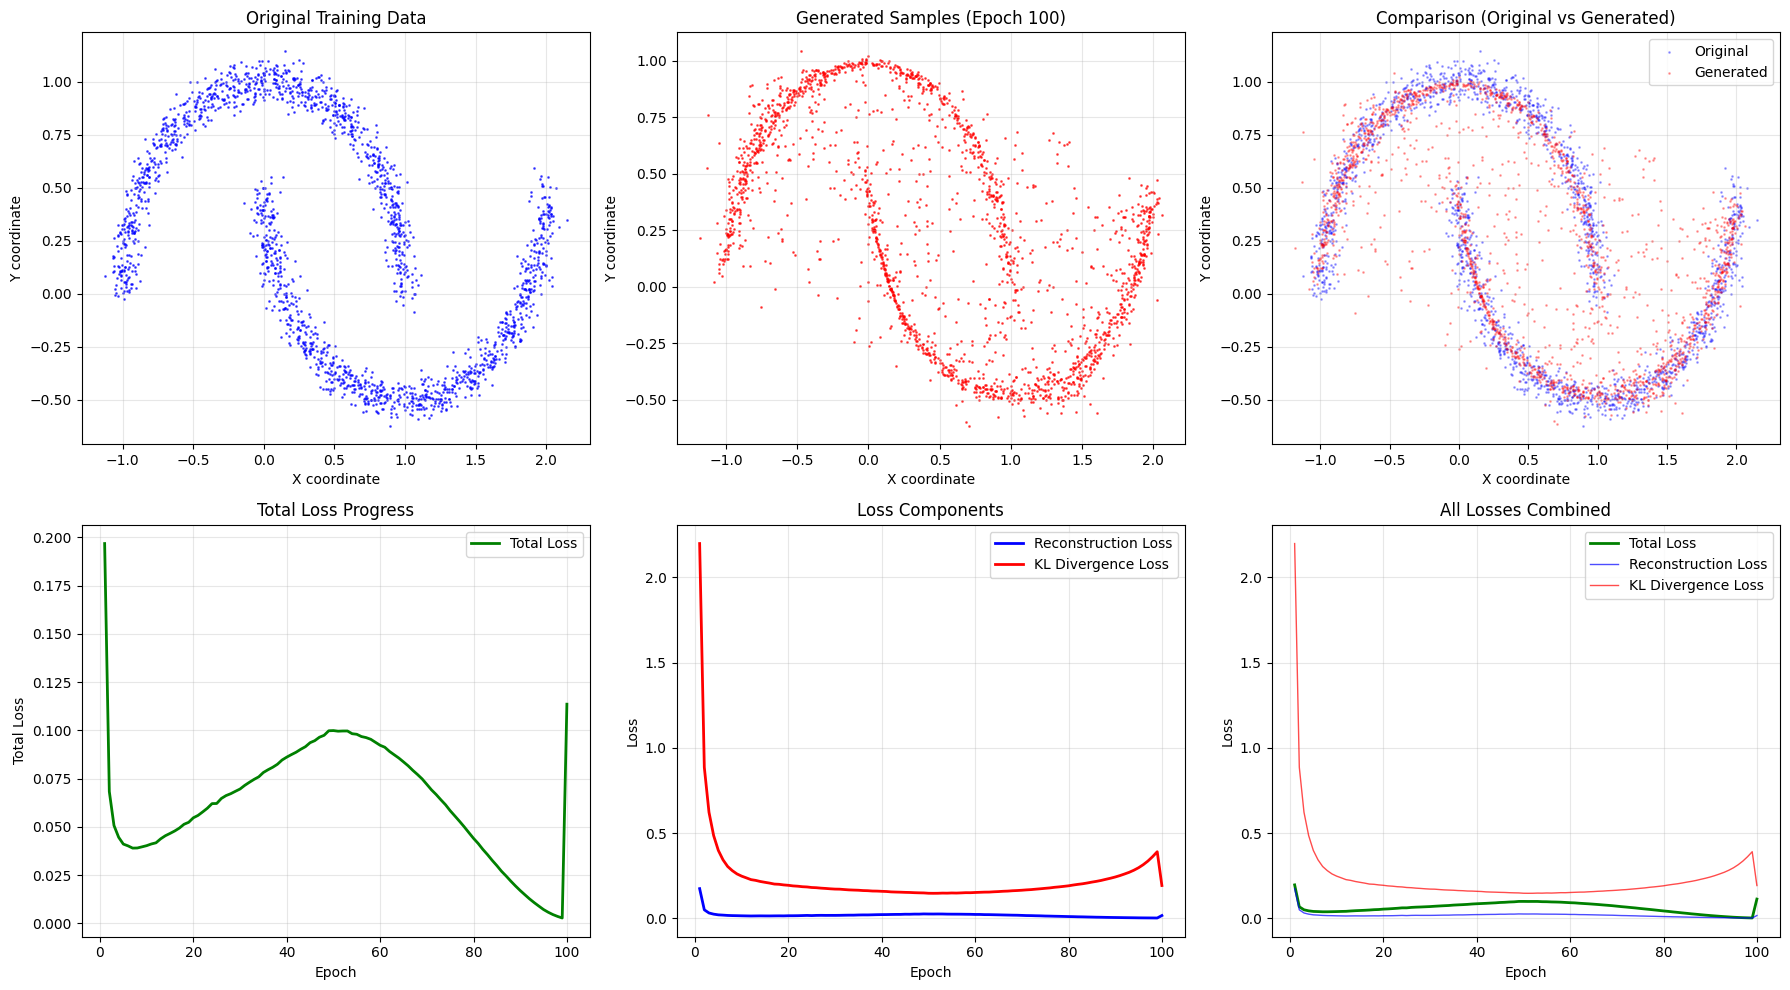

📈 Epoch 100 Summary:
   Total Loss: 0.1136
   Reconstruction Loss: 0.0170
   KL Divergence Loss: 0.1931
   Beta: 0.500
   Learning Rate: 0.000063

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/50000 (0%)]	Total Loss: 0.098743	Recon Loss: 0.021007	KL Loss: 0.155625	Beta: 0.500
Epoch: 101 [12800/50000 (26%)]	Total Loss: 0.099084	Recon Loss: 0.023008	KL Loss: 0.152302	Beta: 0.500
Epoch: 101 [25600/50000 (51%)]	Total Loss: 0.099086	Recon Loss: 0.023495	KL Loss: 0.151331	Beta: 0.500
Epoch: 101 [38400/50000 (77%)]	Total Loss: 0.095965	Recon Loss: 0.018798	KL Loss: 0.154487	Beta: 0.500
====> Epoch: 101 Average Total Loss: 0.0996, Average Recon Loss: 0.0237, Average KL Loss: 0.1518, Beta: 0.500
📈 Epoch 101 Summary:
   Total Loss: 0.0996
   Reconstruction Loss: 0.0237
   KL Divergence Loss: 0.1518
   Beta: 0.500
   Learning Rate: 0.000063

📊 Epoch 102/200
----------------------------------------
Epoch: 102 [0/50000 (0%)]	Total Loss: 0.101080	Recon Loss: 0.026713	KL Loss

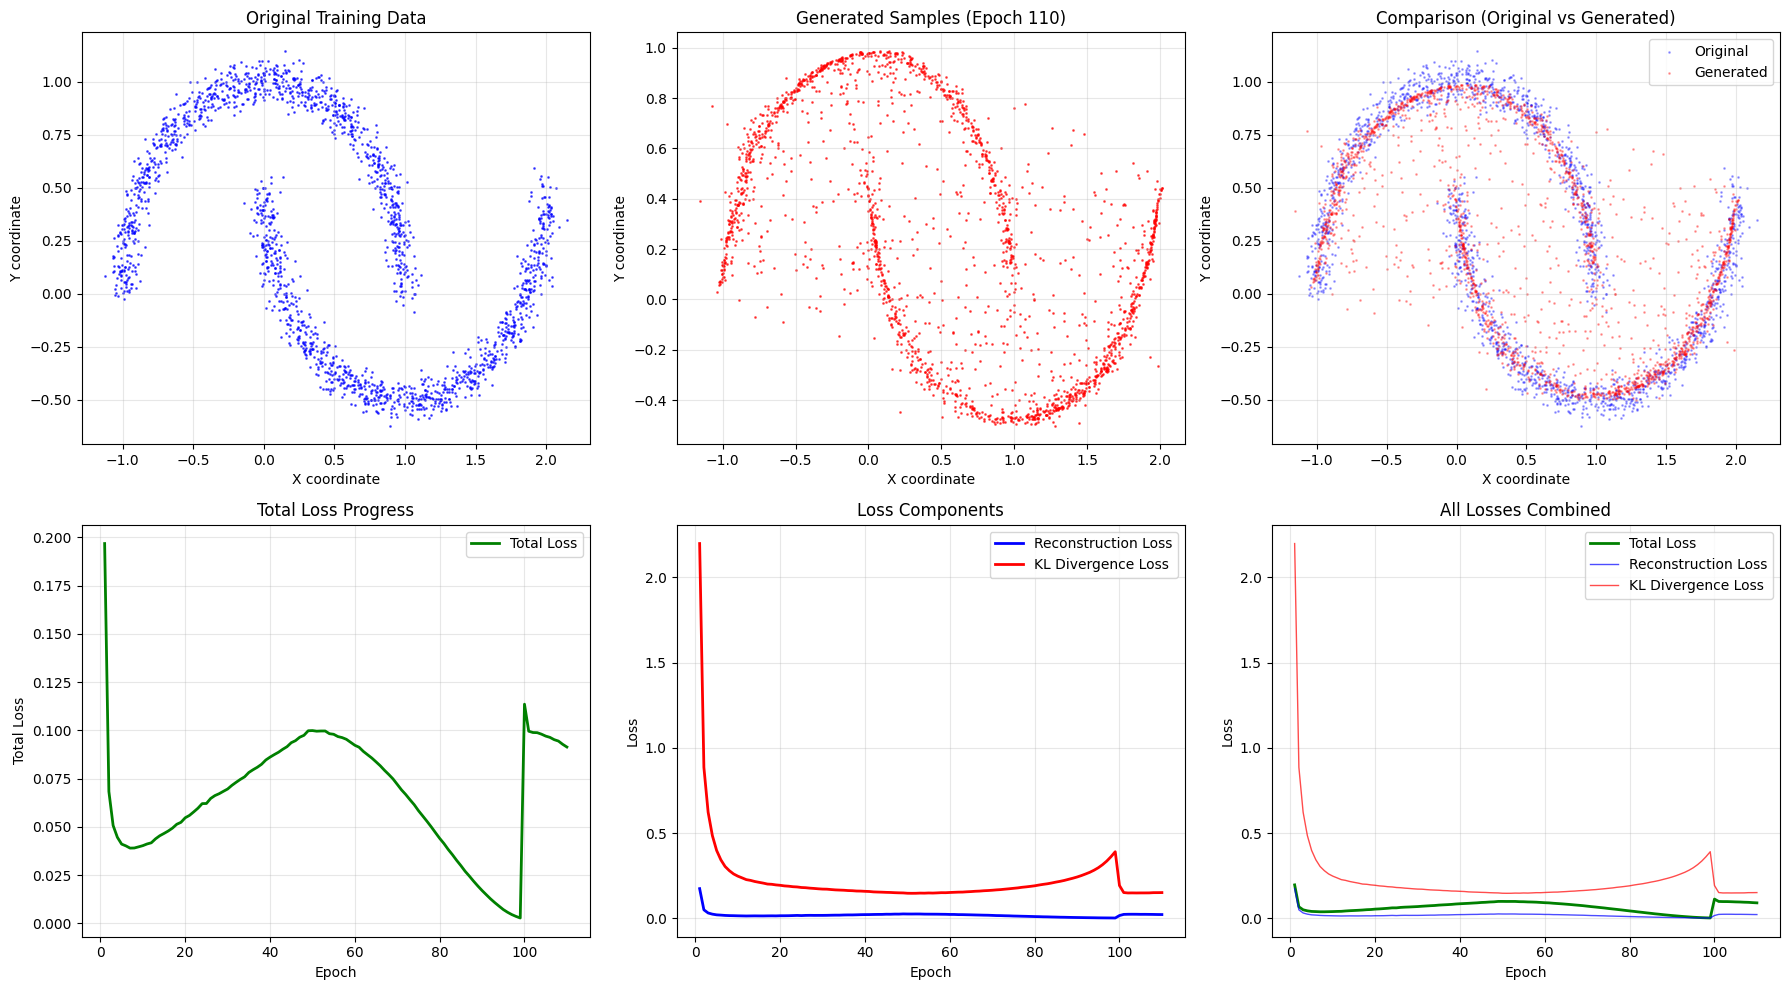

📈 Epoch 110 Summary:
   Total Loss: 0.0914
   Reconstruction Loss: 0.0228
   KL Divergence Loss: 0.1517
   Beta: 0.452
   Learning Rate: 0.000063

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/50000 (0%)]	Total Loss: 0.091009	Recon Loss: 0.022554	KL Loss: 0.154657	Beta: 0.443
Epoch: 111 [12800/50000 (26%)]	Total Loss: 0.090917	Recon Loss: 0.024405	KL Loss: 0.150267	Beta: 0.443
Epoch: 111 [25600/50000 (51%)]	Total Loss: 0.085727	Recon Loss: 0.017322	KL Loss: 0.154544	Beta: 0.443
Epoch: 111 [38400/50000 (77%)]	Total Loss: 0.091307	Recon Loss: 0.023065	KL Loss: 0.154174	Beta: 0.443
====> Epoch: 111 Average Total Loss: 0.0902, Average Recon Loss: 0.0223, Average KL Loss: 0.1533, Beta: 0.443
📈 Epoch 111 Summary:
   Total Loss: 0.0902
   Reconstruction Loss: 0.0223
   KL Divergence Loss: 0.1533
   Beta: 0.443
   Learning Rate: 0.000063

📊 Epoch 112/200
----------------------------------------
Epoch: 112 [0/50000 (0%)]	Total Loss: 0.090800	Recon Loss: 0.025647	KL Loss

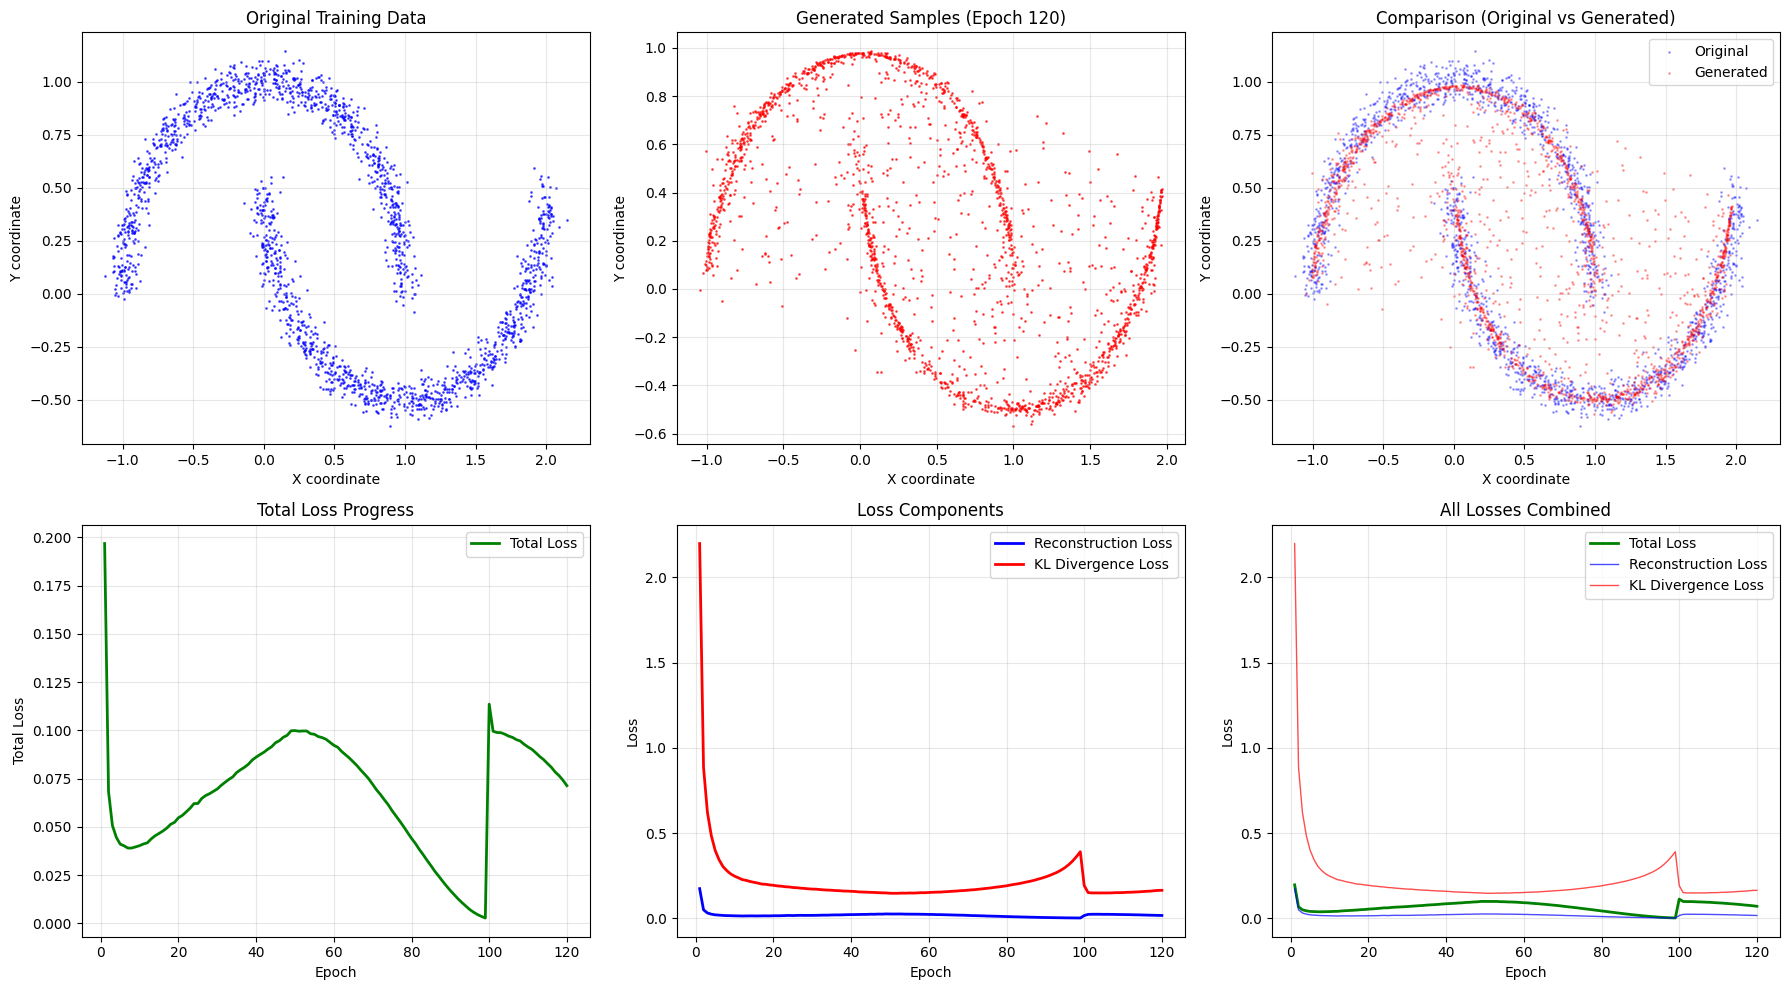

📈 Epoch 120 Summary:
   Total Loss: 0.0714
   Reconstruction Loss: 0.0174
   KL Divergence Loss: 0.1649
   Beta: 0.327
   Learning Rate: 0.000031

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/50000 (0%)]	Total Loss: 0.068817	Recon Loss: 0.016367	KL Loss: 0.168015	Beta: 0.312
Epoch: 121 [12800/50000 (26%)]	Total Loss: 0.069716	Recon Loss: 0.018055	KL Loss: 0.165490	Beta: 0.312
Epoch: 121 [25600/50000 (51%)]	Total Loss: 0.071148	Recon Loss: 0.018755	KL Loss: 0.167833	Beta: 0.312
Epoch: 121 [38400/50000 (77%)]	Total Loss: 0.068624	Recon Loss: 0.016612	KL Loss: 0.166611	Beta: 0.312
====> Epoch: 121 Average Total Loss: 0.0688, Average Recon Loss: 0.0167, Average KL Loss: 0.1671, Beta: 0.312
📈 Epoch 121 Summary:
   Total Loss: 0.0688
   Reconstruction Loss: 0.0167
   KL Divergence Loss: 0.1671
   Beta: 0.312
   Learning Rate: 0.000031

📊 Epoch 122/200
----------------------------------------
Epoch: 122 [0/50000 (0%)]	Total Loss: 0.066571	Recon Loss: 0.016834	KL Loss

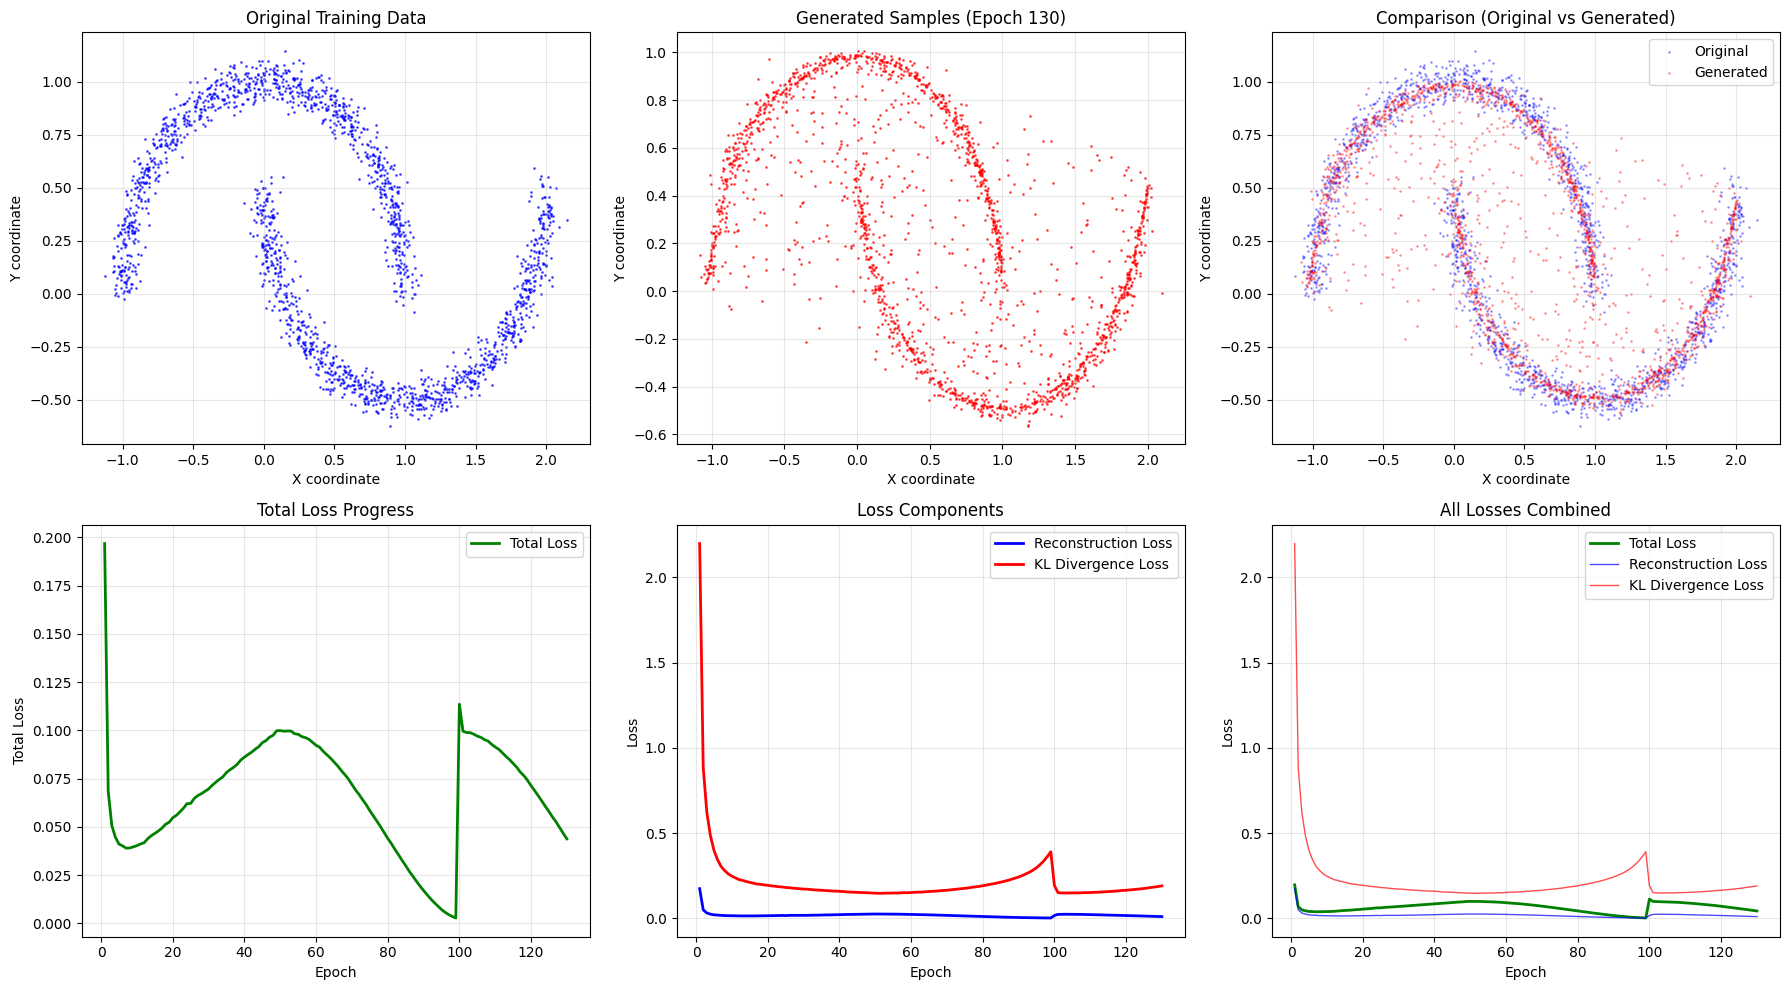

📈 Epoch 130 Summary:
   Total Loss: 0.0438
   Reconstruction Loss: 0.0108
   KL Divergence Loss: 0.1909
   Beta: 0.173
   Learning Rate: 0.000031

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/50000 (0%)]	Total Loss: 0.041314	Recon Loss: 0.010863	KL Loss: 0.192763	Beta: 0.158
Epoch: 131 [12800/50000 (26%)]	Total Loss: 0.041073	Recon Loss: 0.010539	KL Loss: 0.193291	Beta: 0.158
Epoch: 131 [25600/50000 (51%)]	Total Loss: 0.040054	Recon Loss: 0.008983	KL Loss: 0.196693	Beta: 0.158
Epoch: 131 [38400/50000 (77%)]	Total Loss: 0.042708	Recon Loss: 0.011956	KL Loss: 0.194675	Beta: 0.158
====> Epoch: 131 Average Total Loss: 0.0407, Average Recon Loss: 0.0100, Average KL Loss: 0.1943, Beta: 0.158
📈 Epoch 131 Summary:
   Total Loss: 0.0407
   Reconstruction Loss: 0.0100
   KL Divergence Loss: 0.1943
   Beta: 0.158
   Learning Rate: 0.000031

📊 Epoch 132/200
----------------------------------------
Epoch: 132 [0/50000 (0%)]	Total Loss: 0.037343	Recon Loss: 0.009414	KL Loss

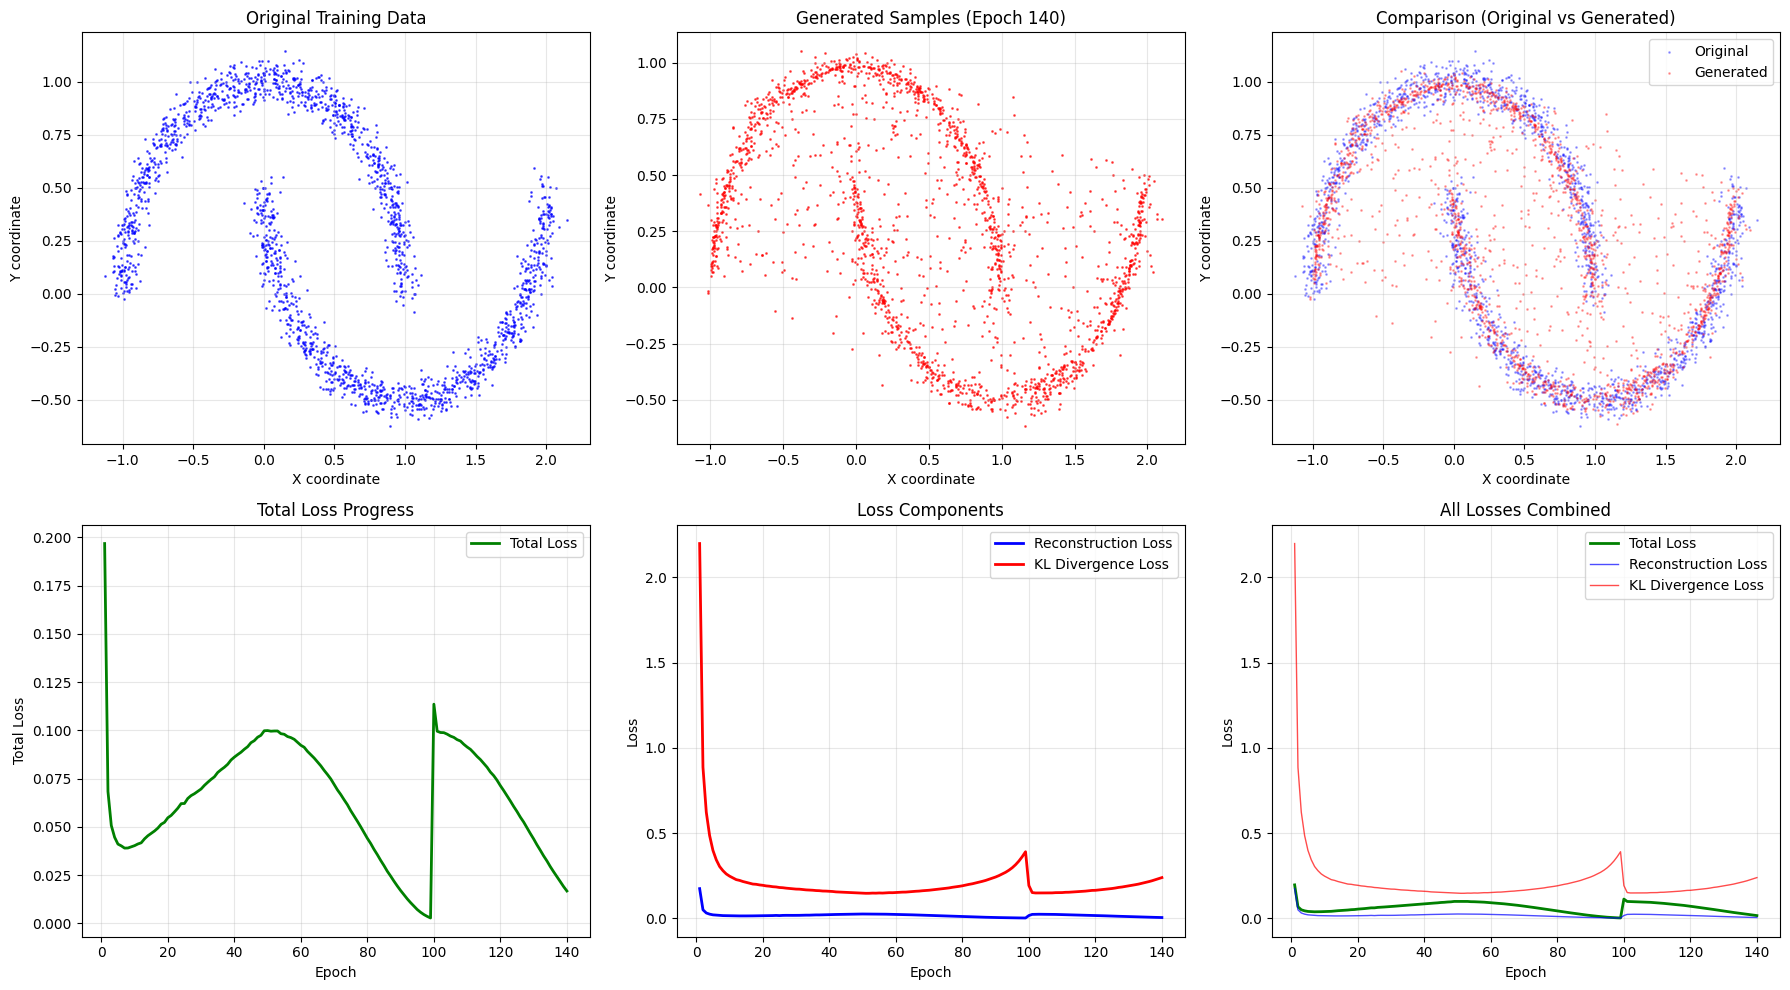

📈 Epoch 140 Summary:
   Total Loss: 0.0168
   Reconstruction Loss: 0.0053
   KL Divergence Loss: 0.2396
   Beta: 0.048
   Learning Rate: 0.000031

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/50000 (0%)]	Total Loss: 0.013849	Recon Loss: 0.004457	KL Loss: 0.241318	Beta: 0.039
Epoch: 141 [12800/50000 (26%)]	Total Loss: 0.014525	Recon Loss: 0.004964	KL Loss: 0.245658	Beta: 0.039
Epoch: 141 [25600/50000 (51%)]	Total Loss: 0.013804	Recon Loss: 0.004187	KL Loss: 0.247110	Beta: 0.039
Epoch: 141 [38400/50000 (77%)]	Total Loss: 0.016517	Recon Loss: 0.006795	KL Loss: 0.249808	Beta: 0.039
====> Epoch: 141 Average Total Loss: 0.0145, Average Recon Loss: 0.0049, Average KL Loss: 0.2468, Beta: 0.039
📈 Epoch 141 Summary:
   Total Loss: 0.0145
   Reconstruction Loss: 0.0049
   KL Divergence Loss: 0.2468
   Beta: 0.039
   Learning Rate: 0.000016

📊 Epoch 142/200
----------------------------------------
Epoch: 142 [0/50000 (0%)]	Total Loss: 0.011804	Recon Loss: 0.004167	KL Loss

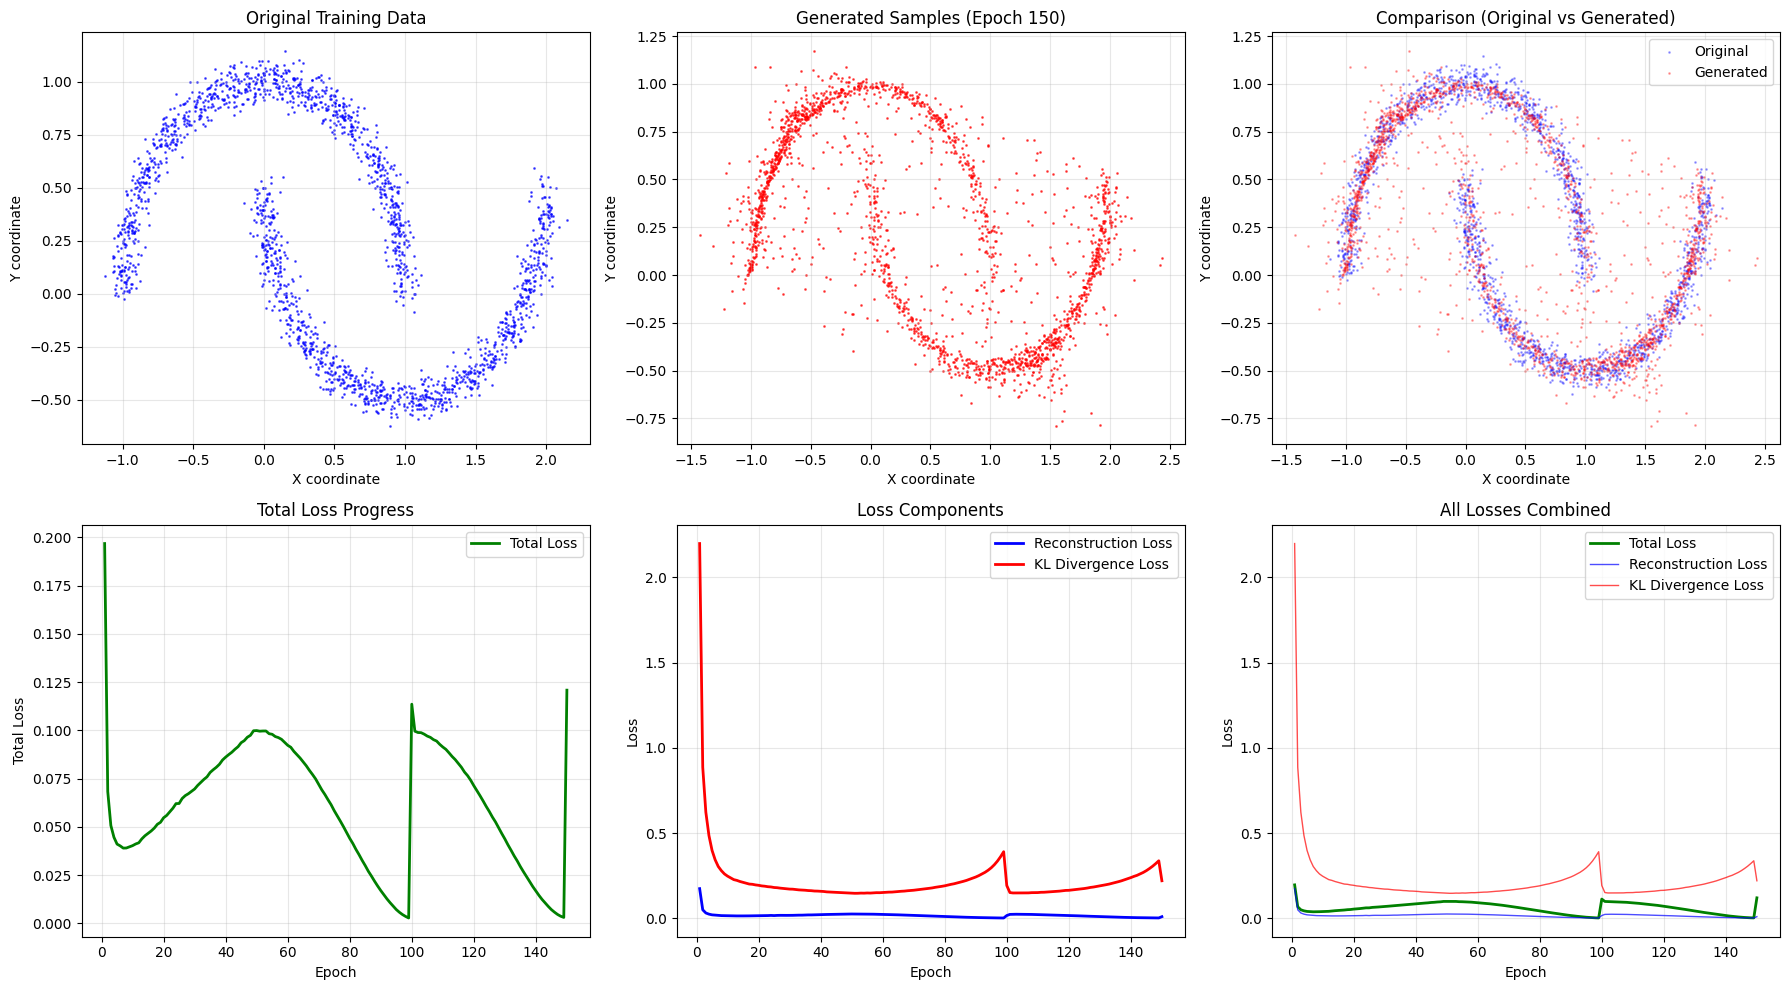

📈 Epoch 150 Summary:
   Total Loss: 0.1209
   Reconstruction Loss: 0.0104
   KL Divergence Loss: 0.2210
   Beta: 0.500
   Learning Rate: 0.000016

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/50000 (0%)]	Total Loss: 0.104382	Recon Loss: 0.012849	KL Loss: 0.183246	Beta: 0.500
Epoch: 151 [12800/50000 (26%)]	Total Loss: 0.106929	Recon Loss: 0.019938	KL Loss: 0.174153	Beta: 0.500
Epoch: 151 [25600/50000 (51%)]	Total Loss: 0.101885	Recon Loss: 0.014369	KL Loss: 0.175205	Beta: 0.500
Epoch: 151 [38400/50000 (77%)]	Total Loss: 0.101276	Recon Loss: 0.015840	KL Loss: 0.171039	Beta: 0.500
====> Epoch: 151 Average Total Loss: 0.1039, Average Recon Loss: 0.0170, Average KL Loss: 0.1741, Beta: 0.500
📈 Epoch 151 Summary:
   Total Loss: 0.1039
   Reconstruction Loss: 0.0170
   KL Divergence Loss: 0.1741
   Beta: 0.500
   Learning Rate: 0.000016

📊 Epoch 152/200
----------------------------------------
Epoch: 152 [0/50000 (0%)]	Total Loss: 0.098706	Recon Loss: 0.015008	KL Loss

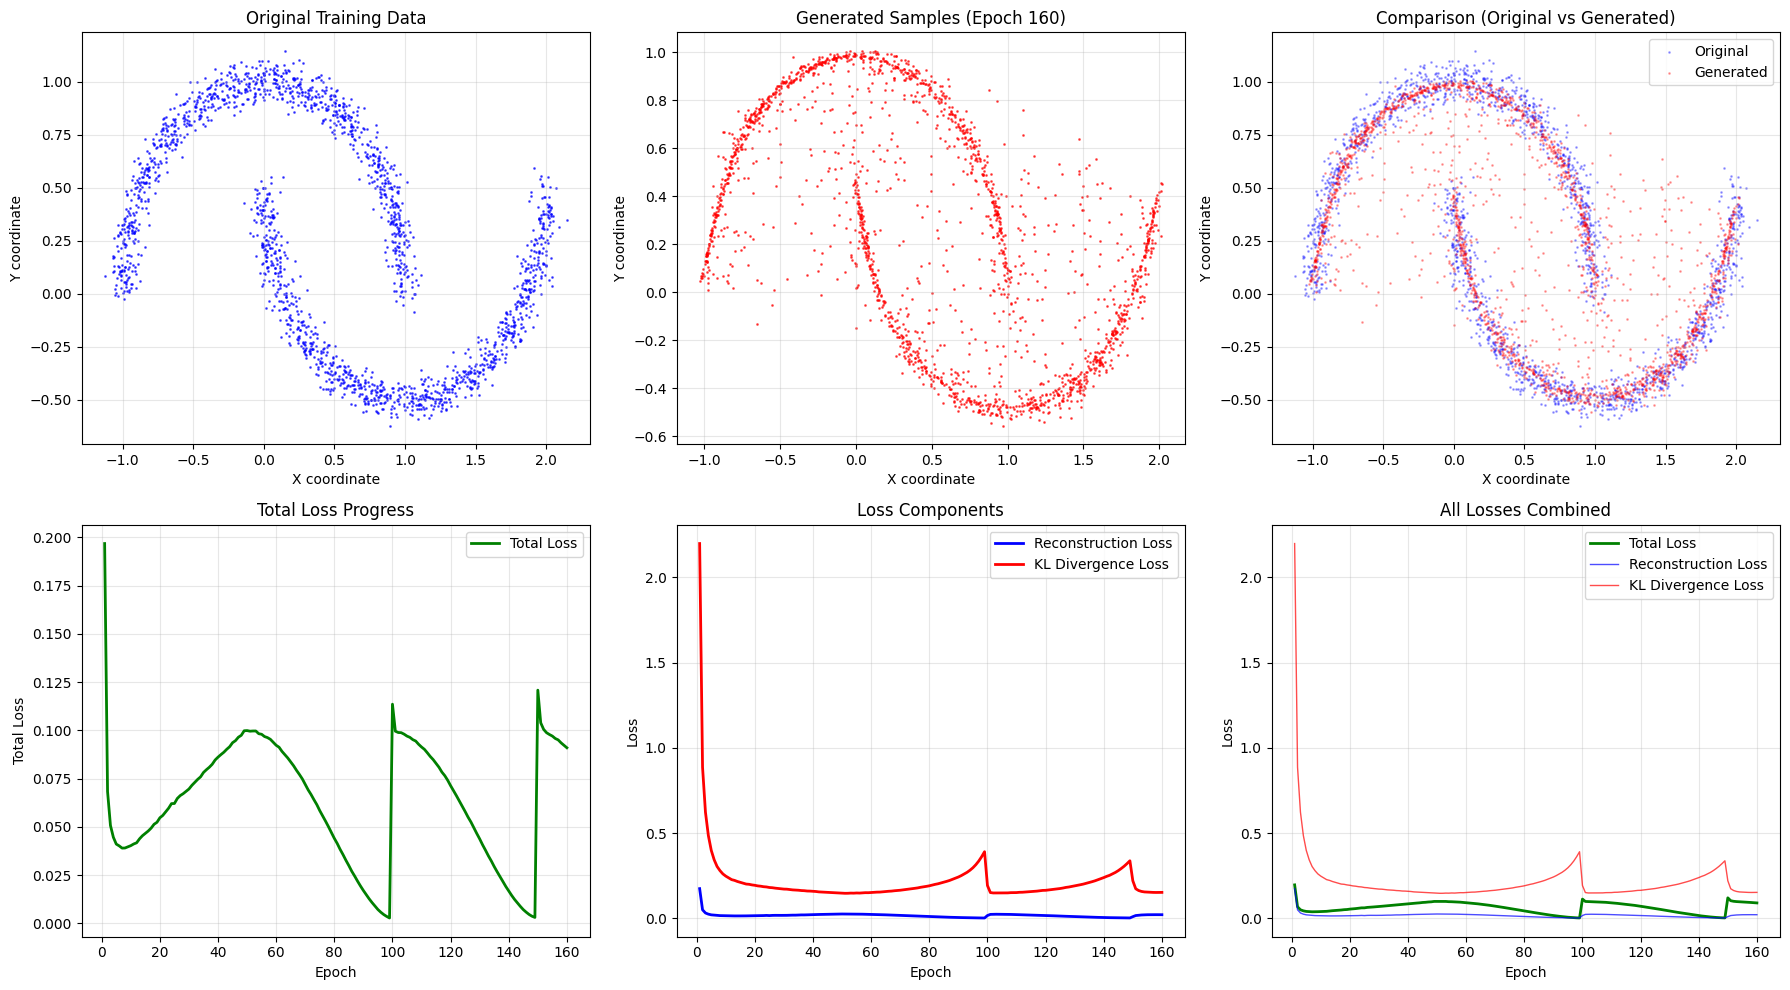

📈 Epoch 160 Summary:
   Total Loss: 0.0910
   Reconstruction Loss: 0.0219
   KL Divergence Loss: 0.1528
   Beta: 0.452
   Learning Rate: 0.000016

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/50000 (0%)]	Total Loss: 0.086420	Recon Loss: 0.019172	KL Loss: 0.151930	Beta: 0.443
Epoch: 161 [12800/50000 (26%)]	Total Loss: 0.088447	Recon Loss: 0.021261	KL Loss: 0.151788	Beta: 0.443
Epoch: 161 [25600/50000 (51%)]	Total Loss: 0.088824	Recon Loss: 0.020859	KL Loss: 0.153548	Beta: 0.443
Epoch: 161 [38400/50000 (77%)]	Total Loss: 0.086666	Recon Loss: 0.017584	KL Loss: 0.156072	Beta: 0.443
====> Epoch: 161 Average Total Loss: 0.0894, Average Recon Loss: 0.0213, Average KL Loss: 0.1538, Beta: 0.443
📈 Epoch 161 Summary:
   Total Loss: 0.0894
   Reconstruction Loss: 0.0213
   KL Divergence Loss: 0.1538
   Beta: 0.443
   Learning Rate: 0.000016

📊 Epoch 162/200
----------------------------------------
Epoch: 162 [0/50000 (0%)]	Total Loss: 0.088554	Recon Loss: 0.021337	KL Loss

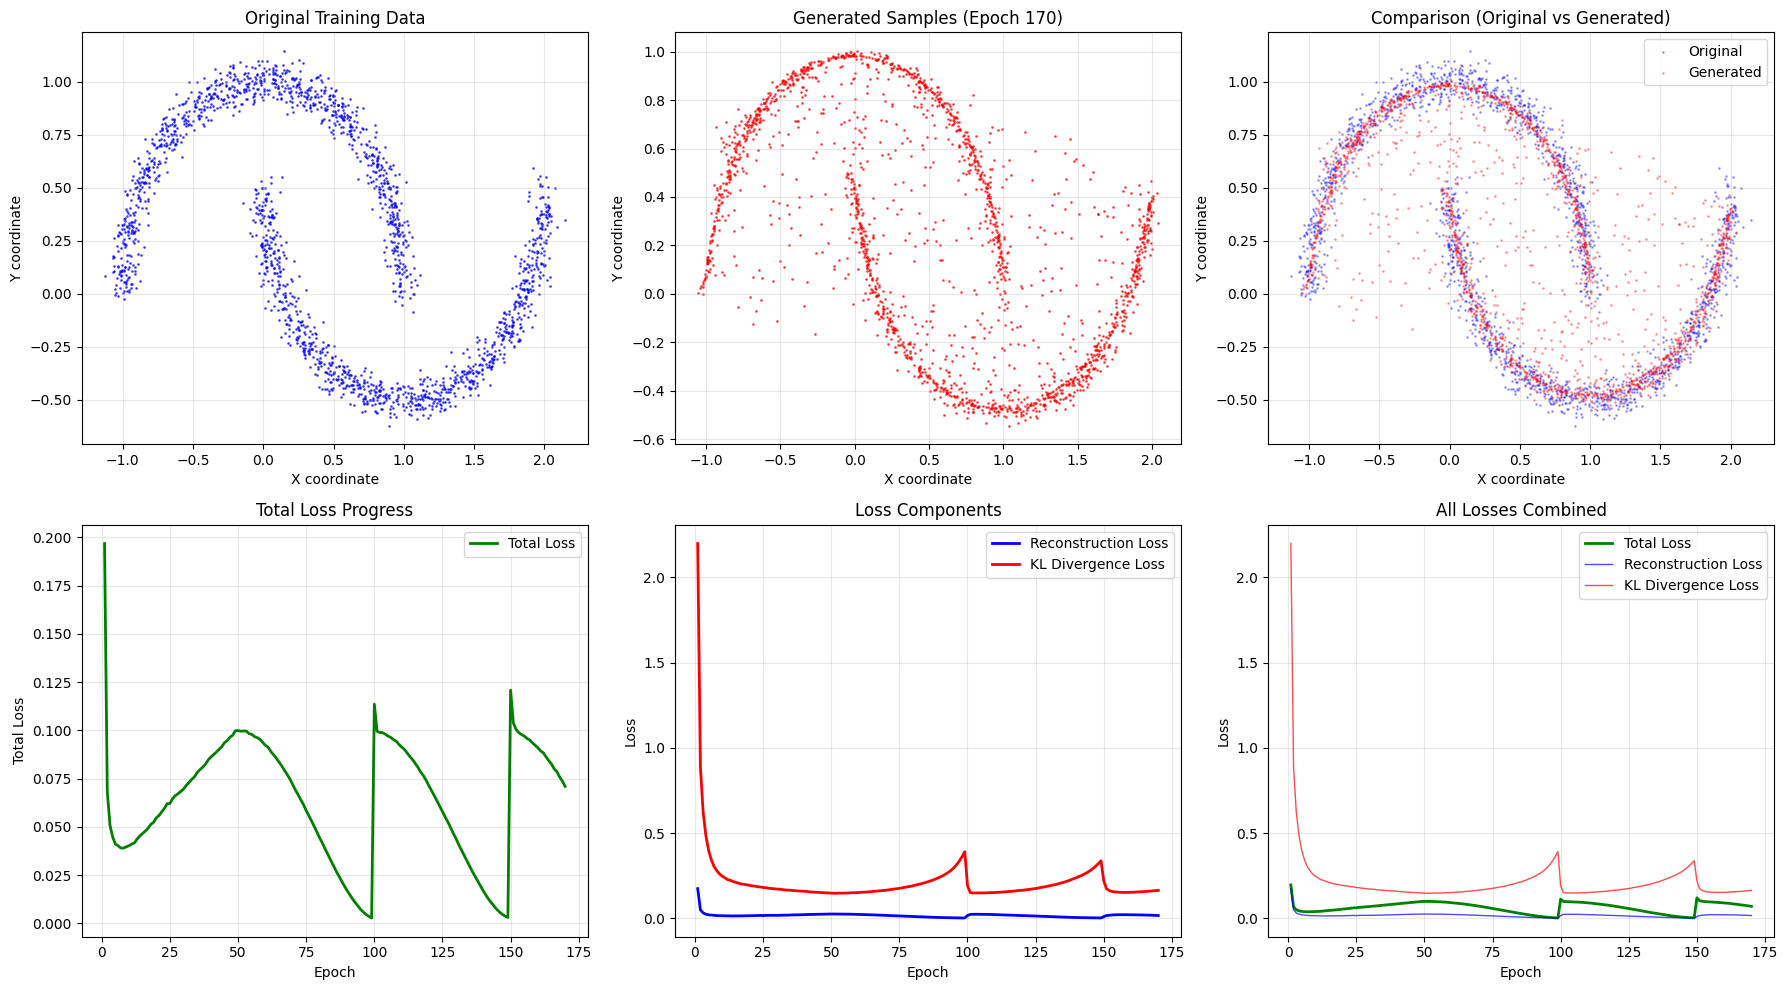

📈 Epoch 170 Summary:
   Total Loss: 0.0710
   Reconstruction Loss: 0.0171
   KL Divergence Loss: 0.1646
   Beta: 0.327
   Learning Rate: 0.000008

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/50000 (0%)]	Total Loss: 0.065123	Recon Loss: 0.013569	KL Loss: 0.165144	Beta: 0.312
Epoch: 171 [12800/50000 (26%)]	Total Loss: 0.065003	Recon Loss: 0.013676	KL Loss: 0.164420	Beta: 0.312
Epoch: 171 [25600/50000 (51%)]	Total Loss: 0.067698	Recon Loss: 0.015596	KL Loss: 0.166901	Beta: 0.312
Epoch: 171 [38400/50000 (77%)]	Total Loss: 0.070198	Recon Loss: 0.017805	KL Loss: 0.167834	Beta: 0.312
====> Epoch: 171 Average Total Loss: 0.0685, Average Recon Loss: 0.0167, Average KL Loss: 0.1658, Beta: 0.312
📈 Epoch 171 Summary:
   Total Loss: 0.0685
   Reconstruction Loss: 0.0167
   KL Divergence Loss: 0.1658
   Beta: 0.312
   Learning Rate: 0.000008

📊 Epoch 172/200
----------------------------------------
Epoch: 172 [0/50000 (0%)]	Total Loss: 0.064539	Recon Loss: 0.015415	KL Loss

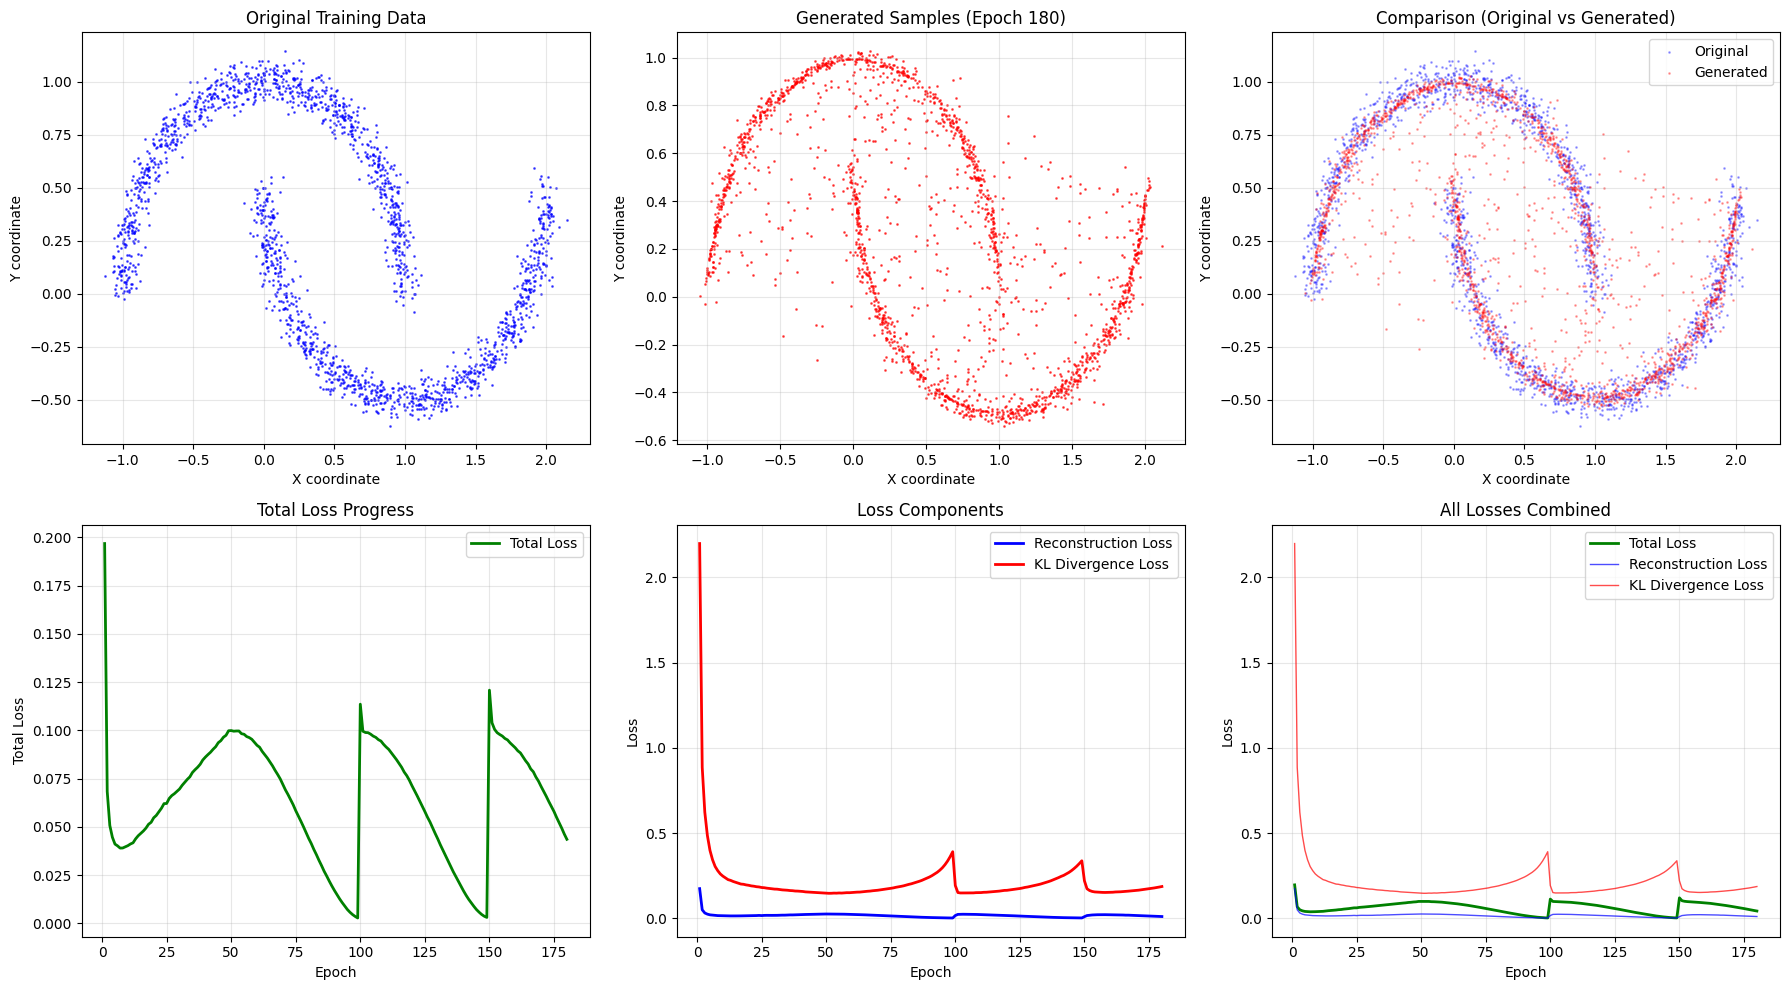

📈 Epoch 180 Summary:
   Total Loss: 0.0436
   Reconstruction Loss: 0.0112
   KL Divergence Loss: 0.1872
   Beta: 0.173
   Learning Rate: 0.000008

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/50000 (0%)]	Total Loss: 0.039459	Recon Loss: 0.009522	KL Loss: 0.189516	Beta: 0.158
Epoch: 181 [12800/50000 (26%)]	Total Loss: 0.040674	Recon Loss: 0.010931	KL Loss: 0.188288	Beta: 0.158
Epoch: 181 [25600/50000 (51%)]	Total Loss: 0.039715	Recon Loss: 0.009557	KL Loss: 0.190914	Beta: 0.158
Epoch: 181 [38400/50000 (77%)]	Total Loss: 0.041160	Recon Loss: 0.010865	KL Loss: 0.191776	Beta: 0.158
====> Epoch: 181 Average Total Loss: 0.0408, Average Recon Loss: 0.0108, Average KL Loss: 0.1903, Beta: 0.158
📈 Epoch 181 Summary:
   Total Loss: 0.0408
   Reconstruction Loss: 0.0108
   KL Divergence Loss: 0.1903
   Beta: 0.158
   Learning Rate: 0.000008

📊 Epoch 182/200
----------------------------------------
Epoch: 182 [0/50000 (0%)]	Total Loss: 0.037418	Recon Loss: 0.009582	KL Loss

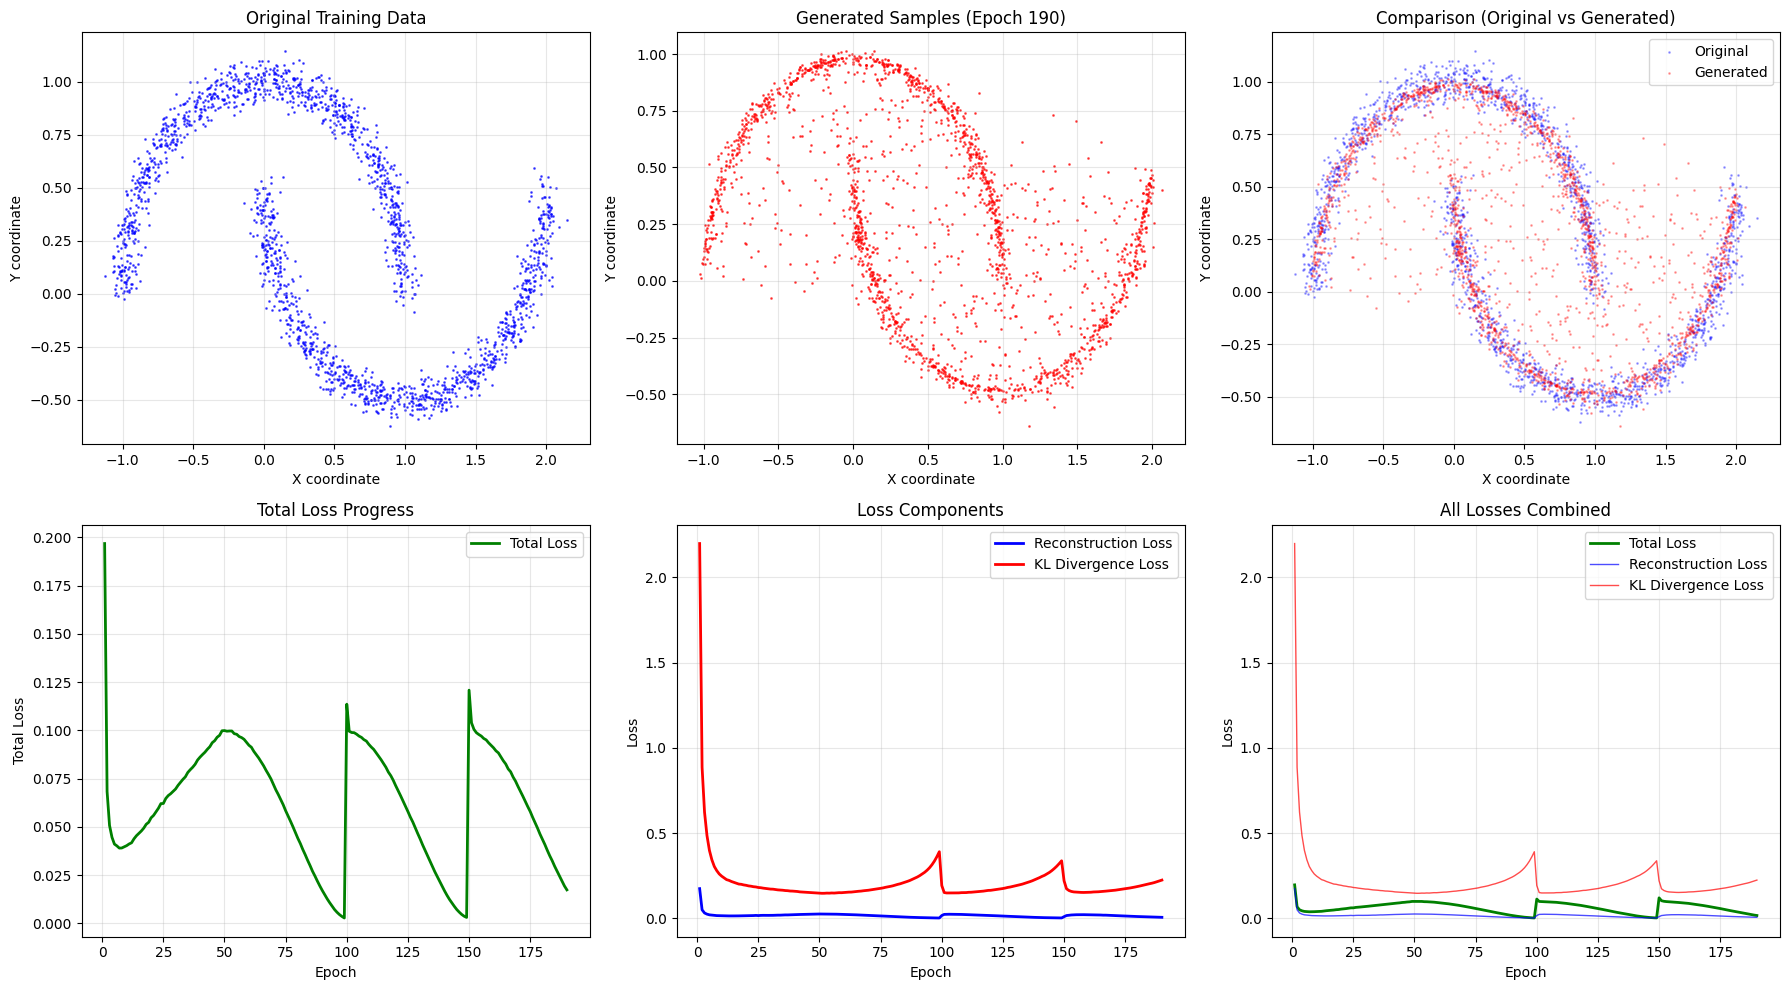

📈 Epoch 190 Summary:
   Total Loss: 0.0173
   Reconstruction Loss: 0.0066
   KL Divergence Loss: 0.2250
   Beta: 0.048
   Learning Rate: 0.000004

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/50000 (0%)]	Total Loss: 0.014666	Recon Loss: 0.005763	KL Loss: 0.228776	Beta: 0.039
Epoch: 191 [12800/50000 (26%)]	Total Loss: 0.015369	Recon Loss: 0.006564	KL Loss: 0.226248	Beta: 0.039
Epoch: 191 [25600/50000 (51%)]	Total Loss: 0.014783	Recon Loss: 0.005855	KL Loss: 0.229400	Beta: 0.039
Epoch: 191 [38400/50000 (77%)]	Total Loss: 0.015290	Recon Loss: 0.006457	KL Loss: 0.226973	Beta: 0.039
====> Epoch: 191 Average Total Loss: 0.0150, Average Recon Loss: 0.0060, Average KL Loss: 0.2302, Beta: 0.039
📈 Epoch 191 Summary:
   Total Loss: 0.0150
   Reconstruction Loss: 0.0060
   KL Divergence Loss: 0.2302
   Beta: 0.039
   Learning Rate: 0.000004

📊 Epoch 192/200
----------------------------------------
Epoch: 192 [0/50000 (0%)]	Total Loss: 0.012603	Recon Loss: 0.005371	KL Loss

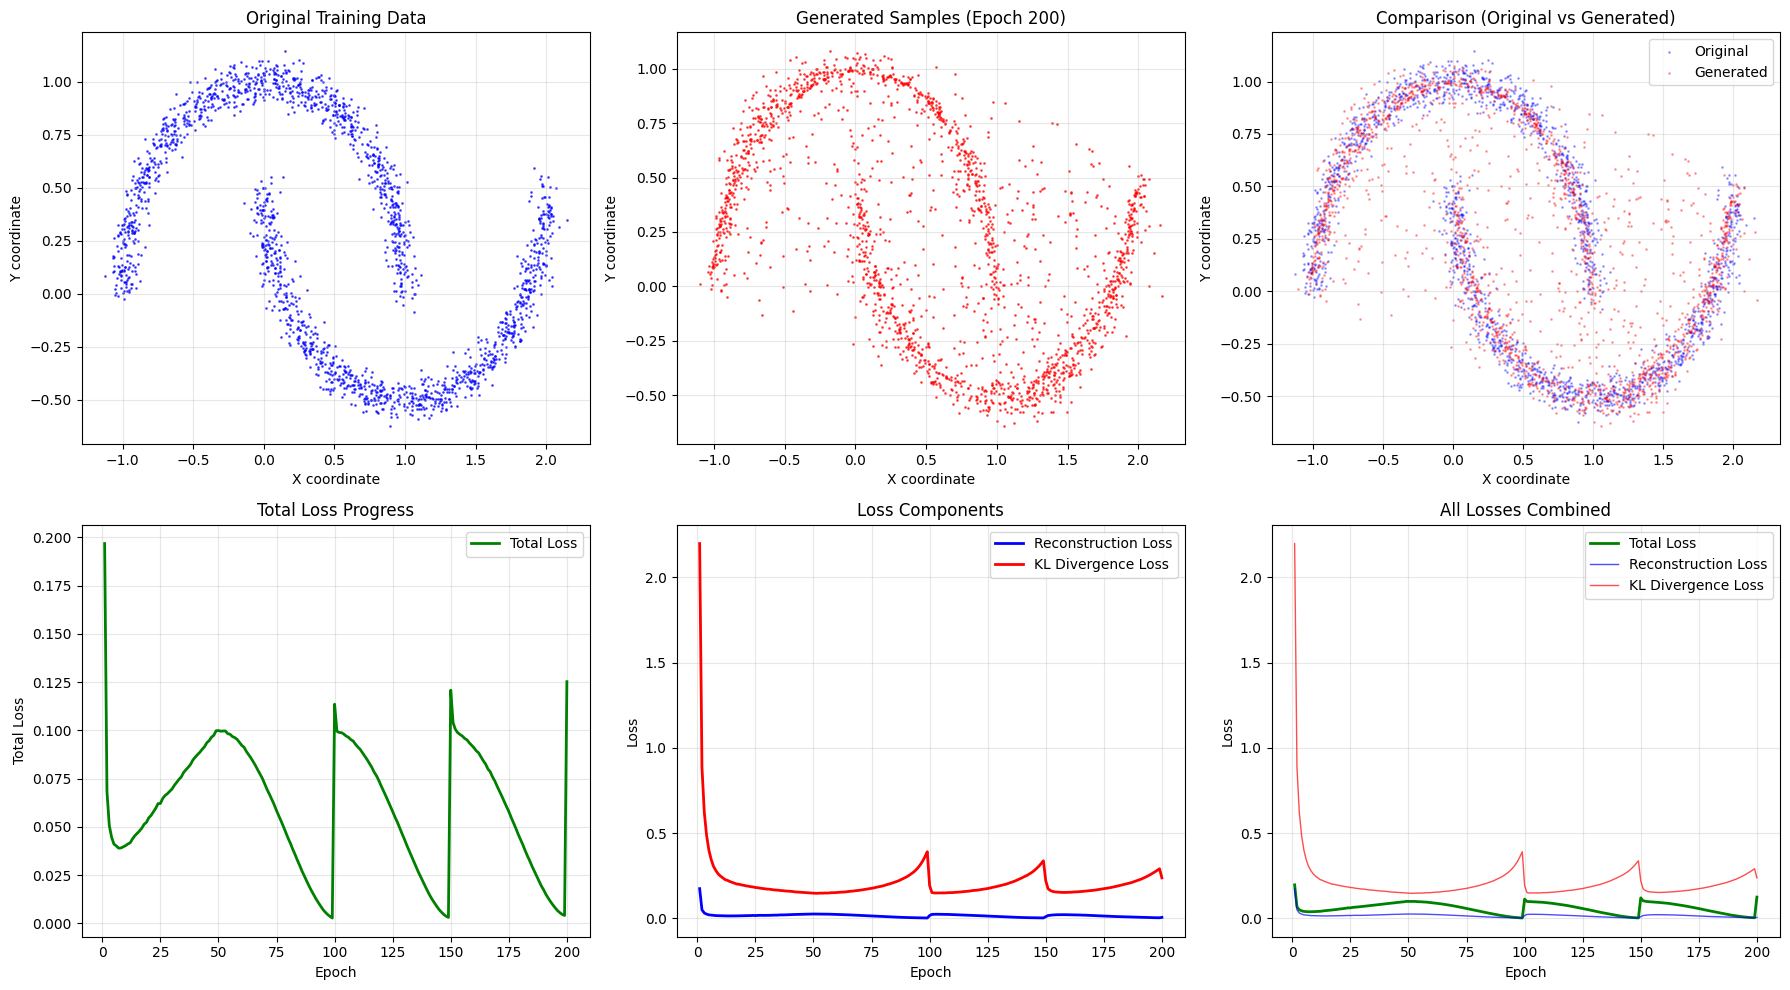

📈 Epoch 200 Summary:
   Total Loss: 0.1253
   Reconstruction Loss: 0.0063
   KL Divergence Loss: 0.2380
   Beta: 0.500
   Learning Rate: 0.000004

🎉 Training completed!
💾 Model saved as 'vae_model.pth'

🎨 Final comprehensive visualization:
💾 Saved plot: vae_results/vae_progress_epoch_200.png


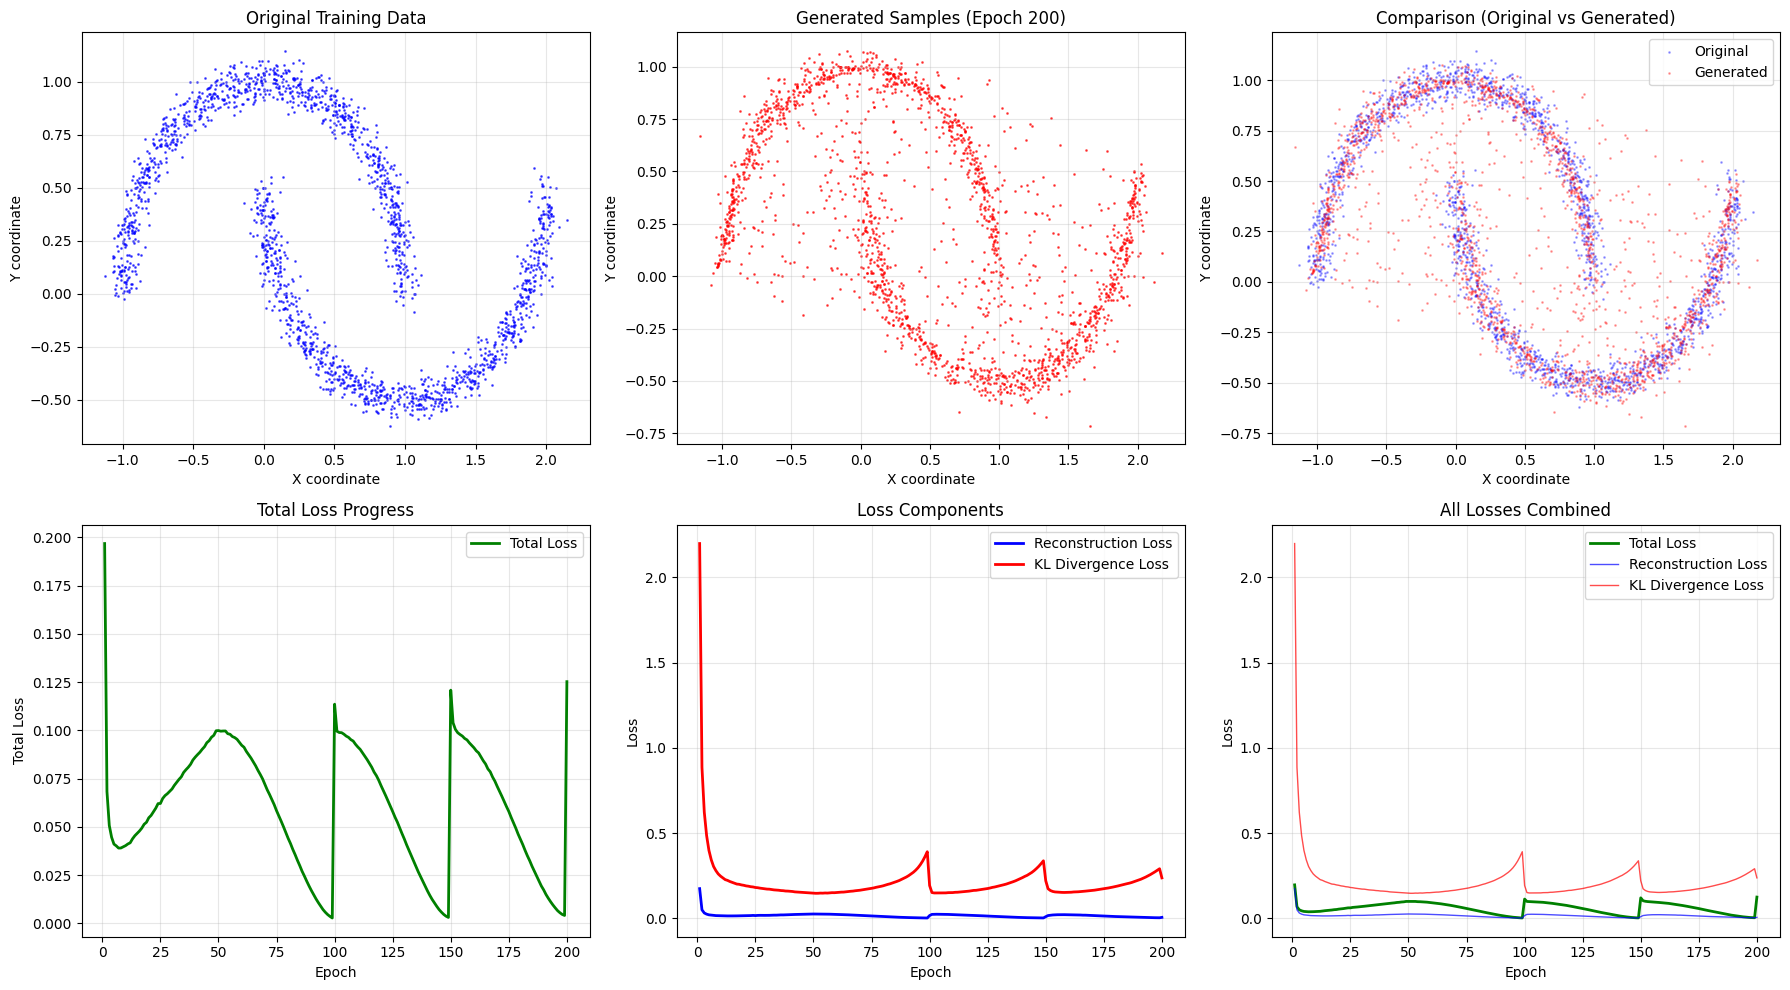

📊 Training progress visualized above!
   Watch how the losses decrease as the model learns!
   The VAE learns to balance reconstruction quality with latent space structure!


In [9]:
# Training loop
print("🎯 Starting VAE training...")
print("=" * 60)

# Lists to track training progress
total_losses = []
recon_losses = []
kl_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")
visualize_training_progress(0, [], [], [], save_plot=True)

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch
    avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta = train_epoch(epoch)
    
    # Track losses
    total_losses.append(avg_total_loss)
    recon_losses.append(avg_recon_loss)
    kl_losses.append(avg_kl_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=True)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Total Loss: {avg_total_loss:.4f}")
    print(f"   Reconstruction Loss: {avg_recon_loss:.4f}")
    print(f"   KL Divergence Loss: {avg_kl_loss:.4f}")
    print(f"   Beta: {current_beta:.3f}")
    print(f"   Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained model
torch.save(vae.state_dict(), 'vae_model.pth')
print("💾 Model saved as 'vae_model.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, total_losses, recon_losses, kl_losses, save_plot=True)

print("📊 Training progress visualized above!")
print("   Watch how the losses decrease as the model learns!")
print("   The VAE learns to balance reconstruction quality with latent space structure!")


## Step 9: Let's Generate New Data! 🎨

Now for the fun part - let's use our trained VAE to create new moon-shaped data! This demonstrates the power of VAEs for generative modeling.


🎨 Generating new moon-shaped data...


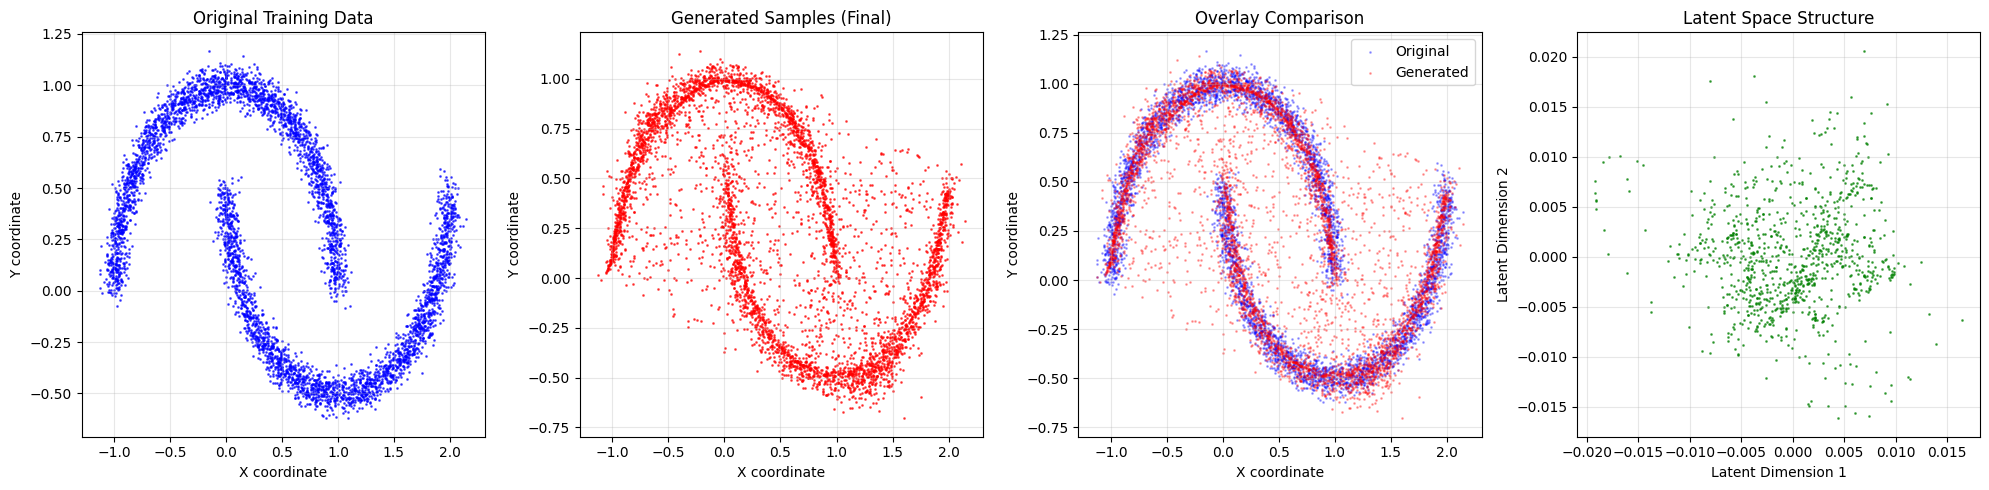

✅ New data generated!
   Compare the shapes - our VAE learned to create moon-shaped data!
   The generated samples should capture the moon structure.
   The latent space shows how the VAE organizes the data internally!


In [10]:
# Generate new samples using our trained VAE
print("🎨 Generating new moon-shaped data...")

# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 5))

# Original training data
plt.subplot(1, 4, 1)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(1, 4, 2)
plt.scatter(generated_samples[:, 0], generated_samples[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples (Final)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(1, 4, 3)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(generated_samples[:, 0], generated_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)

# Show the latent space structure
plt.subplot(1, 4, 4)
# Encode some real data to see latent space
vae.eval()
with torch.no_grad():
    real_batch = torch.from_numpy(train_data[:1000]).to(device).float()
    mu, logvar = vae.encode(real_batch)
    latent_points = mu.cpu().numpy()

plt.scatter(latent_points[:, 0], latent_points[:, 1], c='green', s=1, alpha=0.6)
plt.title('Latent Space Structure')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ New data generated!")
print("   Compare the shapes - our VAE learned to create moon-shaped data!")
print("   The generated samples should capture the moon structure.")
print("   The latent space shows how the VAE organizes the data internally!")


## 🎉 Congratulations! You've Built a VAE!

You've successfully implemented and trained a Variational Autoencoder (VAE)! Let's summarize what we accomplished:

### What We Learned:
1. **VAEs**: Probabilistic generative models that learn data representations
2. **Encoder**: Compresses data into a lower-dimensional latent space
3. **Decoder**: Reconstructs data from latent representations
4. **Reparameterization Trick**: Enables gradient-based training with stochastic sampling
5. **ELBO Loss**: Balances reconstruction quality with latent space regularization

### Key Concepts:
- **Latent Space**: A compressed representation where similar data points are close together
- **KL Divergence**: Measures how different the learned distribution is from a standard Gaussian
- **Beta Parameter**: Controls the balance between reconstruction and regularization
- **Stochastic Generation**: Can generate new data by sampling from the latent space

### What Makes VAEs Special:
- ✅ **Probabilistic**: Learns a distribution over latent variables
- ✅ **Continuous Latent Space**: Smooth interpolation between data points
- ✅ **Explicit Likelihood**: Can compute approximate likelihoods
- ✅ **Structured Latent Space**: Well-organized representations for downstream tasks


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rate (try 1e-4, 1e-2)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust beta parameter (try 0.1, 2.0, 10.0)
3. **Visualize Training**: Watch how the latent space evolves during training

### Intermediate Experiments:
4. **Different Latent Dimensions**: Try 1D, 3D, or 4D latent spaces
5. **Beta-VAE**: Experiment with different beta values to control disentanglement
6. **Conditional VAE**: Generate different types of data based on labels

### Advanced Experiments:
7. **Higher Dimensions**: Apply to image data (MNIST, CIFAR-10)
8. **WAE (Wasserstein Autoencoder)**: Implement the Wasserstein variant
9. **VAE-GAN**: Combine VAE with GAN for better generation quality

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
LATENT_DIM = 4         # Higher dimensional latent space
HIDDEN_DIM = 512       # Larger networks

# Try different beta values
BETA = 0.1             # Less regularization
BETA = 10.0            # More regularization
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original VAE Paper**: "Auto-Encoding Variational Bayes" by Kingma & Welling (2014)
2. **Beta-VAE**: "β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework" by Higgins et al. (2017)
3. **WAE**: "Wasserstein Auto-Encoders" by Tolstikhin et al. (2018)
4. **VAE-GAN**: "Autoencoding beyond pixels using a learned similarity metric" by Larsen et al. (2016)

### Libraries to Explore:
- **PyTorch Lightning**: For easier VAE training
- **Hugging Face Transformers**: For text-based VAEs
- **Pyro**: Probabilistic programming with VAEs

### Applications:
- **Image Generation**: Creating new images from scratch
- **Data Compression**: Learning efficient representations
- **Anomaly Detection**: Finding unusual patterns in data
- **Data Augmentation**: Generating more training data
- **Representation Learning**: Learning useful features for downstream tasks

### Key Takeaways:
- VAEs are powerful tools for generative modeling and representation learning
- The reparameterization trick is crucial for training
- The beta parameter controls the trade-off between reconstruction and regularization
- VAEs provide a principled way to learn continuous latent representations
- The latent space can be used for interpolation and manipulation

### Common VAE Challenges:
- **Blurry Reconstructions**: VAEs tend to produce smoother, less sharp outputs
- **Posterior Collapse**: When the latent space becomes uninformative
- **Beta Tuning**: Finding the right balance between reconstruction and regularization
- **Evaluation**: Measuring VAE quality objectively

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how VAEs work!*
